# Analisis Data Minggu 1 — Coop Monitor (16–23 Oktober 2026)

Notebook ini berisi semua plot data Minggu 1: deret waktu, batas lingkungan dari jurnal, korelasi, plot 3 dimensi, dan ambang peringatan hasil *clustering*.

**Perangkat:** ESP32-C3 SuperMini, sensor gas MQ-135 (modul `mq135-01`), AHT20 (suhu dan kelembapan), BMP280 (tekanan dan suhu).

> **Penting:** nilai MQ-135 di sini adalah **respons relatif** dalam milivolt pada input ADC (setelah pembagi tegangan), **bukan konsentrasi amonia dalam ppm**. Sensor belum dikalibrasi terhadap alat referensi, jadi batas amonia dari jurnal (ppm) hanya ditampilkan sebagai konteks dan **tidak bisa** dibandingkan langsung dengan nilai mV.

Daftar pustaka lengkap dengan DOI ada di bagian akhir. Kode notebook ini membaca empat file `coop-readings (*.csv)` dari folder induk (`Week 1 Readings`).

## 1. Persiapan dan pemuatan data

Langkah pra-pemrosesan:
1. Gabungkan keempat file CSV dan hapus baris duplikat (identitas `deviceId`, `bootId`, `seq`).
2. Ubah waktu `sampledAt` (UTC) ke WIB (Asia/Jakarta).
3. Buang baris berstatus `WARMUP` (pemanasan sensor).
4. Hitung **median 5 menit**. Satu interval dipakai hanya jika berisi minimal 54 dari 60 pembacaan (≥ 90%). Median dipilih karena tahan terhadap lonjakan (*spike*) dan derau.

In [1]:
import sys
from pathlib import Path

# Jika library dipasang di folder lokal proyek (bukan di environment Jupyter), tambahkan ke path.
for cand in [Path('../../outputs/analysis-libs-20261110'), Path('../outputs/analysis-libs-20261110')]:
    if cand.exists():
        sys.path.insert(0, str(cand.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (mengaktifkan proyeksi 3D)
from zoneinfo import ZoneInfo

TZ = ZoneInfo('Asia/Jakarta')
DATA_DIR = Path('..')            # folder 'Week 1 Readings'
files = sorted(DATA_DIR.glob('coop-readings*.csv'))
print('File data:', [f.name for f in files])

raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
n_source = len(raw)
raw = raw.drop_duplicates(subset=['deviceId', 'bootId', 'seq'])
raw['t'] = pd.to_datetime(raw['sampledAt'], utc=True).dt.tz_convert(TZ)
raw = raw.sort_values('t')
for c in ['mqMv', 'ahtTemperatureC', 'bmpTemperatureC', 'humidityPct', 'pressureHpa', 'mqThresholdMv']:
    raw[c] = pd.to_numeric(raw[c], errors='coerce')

df = raw[raw['status'].isin(['OK', 'GAS_WARNING'])].rename(columns={
    'mqMv': 'mq', 'ahtTemperatureC': 'temp', 'bmpTemperatureC': 'temp_bmp',
    'humidityPct': 'rh', 'pressureHpa': 'press'}).copy()

g = df.set_index('t').resample('5min')
b = g[['mq', 'temp', 'temp_bmp', 'rh', 'press']].median()
b = b[g['mq'].count() >= 54].copy()
b['date'] = b.index.strftime('%Y-%m-%d')

print(f'Baris sumber           : {n_source:,}')
print(f'Pembacaan valid (tanpa WARMUP): {len(df):,}')
print(f'Median 5 menit         : {len(b):,}')
print(f'Periode                : {b.index.min():%d %b %Y %H:%M} – {b.index.max():%d %b %Y %H:%M} WIB')
b.describe().round(2)

File data: ['coop-readings (1).csv', 'coop-readings (2).csv', 'coop-readings (3).csv', 'coop-readings (4).csv']
Baris sumber           : 127,719
Pembacaan valid (tanpa WARMUP): 127,678
Median 5 menit         : 2,128
Periode                : 16 Oct 2026 10:10 – 23 Oct 2026 19:25 WIB


,mq,temp,temp_bmp,rh,press
count,2128.00,2128.00,2128.00,2128.00,2128.00
mean,710.55,26.40,27.05,56.27,888.15
std,69.54,2.53,2.58,11.05,1.26
min,503.00,22.02,22.54,27.75,885.11
25%,708.00,24.36,24.97,48.86,887.25
50%,737.00,26.07,26.71,57.26,888.24
75%,754.50,28.74,29.41,65.39,889.07
max,799.00,31.26,31.99,78.94,890.98


## 2. Deret waktu semua sensor

Plot berikut sama dengan `week-1-overview.png` di folder ini: median 5 menit dari setiap sensor. Garis putus-putus merah pada MQ-135 adalah ambang yang tersimpan di perangkat selama Minggu 1 (695,5 mV).

Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):


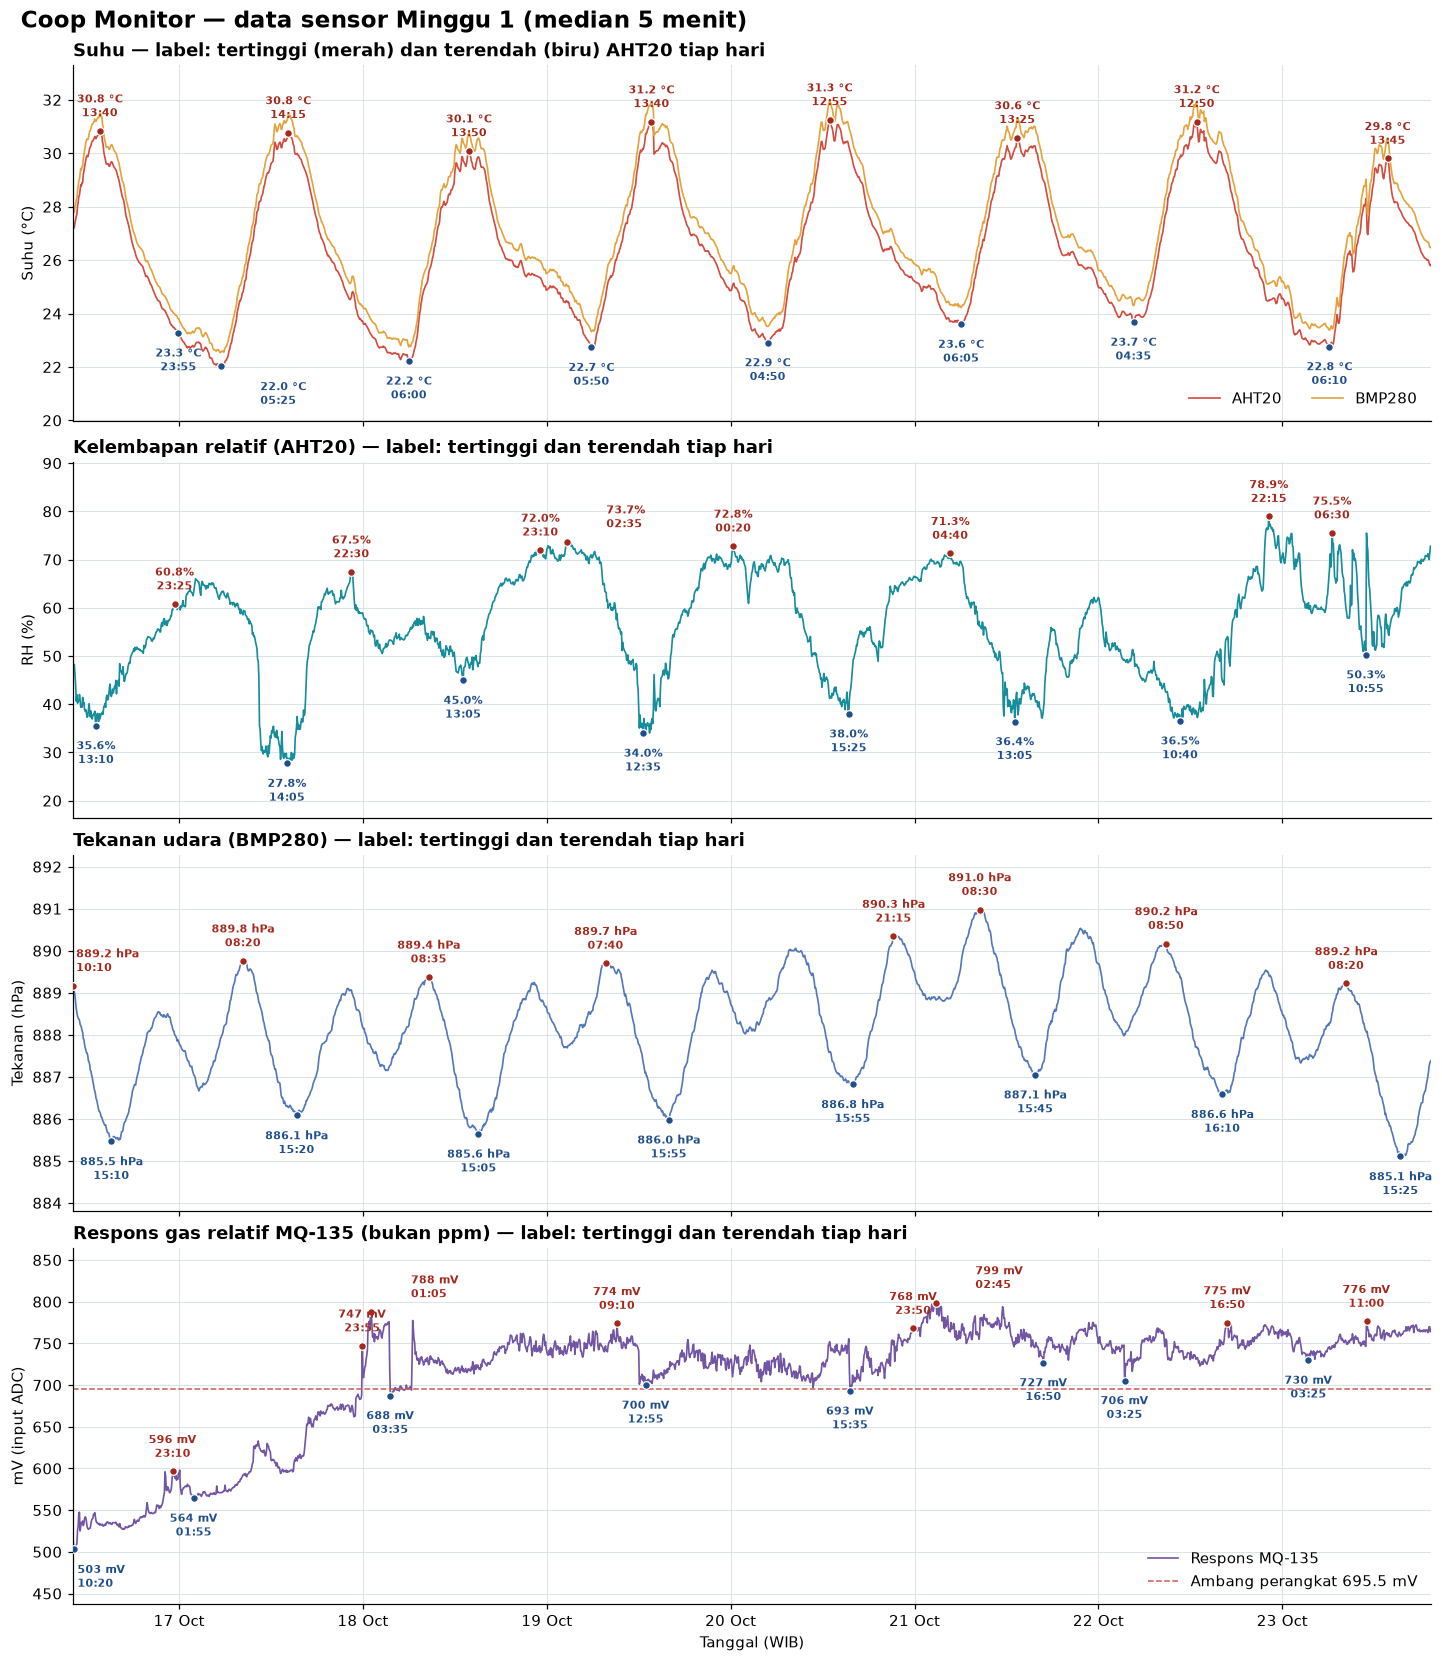

,Tekanan (hPa) maks,jam Tekanan (hPa) maks,Tekanan (hPa) min,jam Tekanan (hPa) min,MQ-135 (mV) maks,jam MQ-135 (mV) maks,MQ-135 (mV) min,jam MQ-135 (mV) min
16 Oct,889.2,10:10,885.5,15:10,596.0,23:10,503.0,10:20
17 Oct,889.8,08:20,886.1,15:20,747.0,23:55,564.0,01:55
18 Oct,889.4,08:35,885.6,15:05,788.0,01:05,688.0,03:35
19 Oct,889.7,07:40,886.0,15:55,774.0,09:10,700.0,12:55
20 Oct,890.3,21:15,886.8,15:55,768.0,23:50,693.0,15:35
21 Oct,891.0,08:30,887.1,15:45,799.0,02:45,727.0,16:50
22 Oct,890.2,08:50,886.6,16:10,775.0,16:50,706.0,03:25
23 Oct,889.2,08:20,885.1,15:25,776.0,11:00,730.0,03:25


In [2]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})

def time_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=TZ))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b', tz=TZ))
    ax.grid(True, color='#dce3e7', linewidth=.7)
    ax.margins(x=0)

def mark_daily(ax, s, unit, color, kind='max', dp=1, above=None):
    # Tandai puncak (kind='max') atau titik terendah (kind='min') setiap hari: nilai dan jam WIB
    if above is None:
        above = kind == 'max'
    prev = None
    for _, day in s.dropna().groupby(s.dropna().index.date):
        t = day.idxmax() if kind == 'max' else day.idxmin()
        v = day.loc[t]
        dx, ha = 0, 'center'
        if prev is not None and (t - prev) < pd.Timedelta(hours=8):
            dx, ha = 26, 'left'   # geser label agar tidak menumpuk dengan label hari sebelumnya
        if t - s.index.min() < pd.Timedelta(hours=3):
            dx, ha = 2, 'left'    # titik di tepi kiri grafik
        elif s.index.max() - t < pd.Timedelta(hours=3):
            dx, ha = -2, 'right'  # titik di tepi kanan grafik
        ax.plot(t, v, 'o', ms=5, color=color, mec='white', mew=.8, zorder=5)
        ax.annotate(f'{v:.{dp}f}{unit}\n{t:%H:%M}', (t, v), textcoords='offset points',
                    xytext=(dx, 7 if above else -9), ha=ha, va='bottom' if above else 'top',
                    fontsize=7.5, color=color, fontweight='bold', zorder=6)
        prev = t

def mark_peaks_lows(ax, s, unit, dp=1, hi_color='#a5281c', lo_color='#1f4e8c', pad=.22):
    # Label puncak (atas) dan terendah (bawah) setiap hari, lalu beri ruang di atas/bawah untuk label
    mark_daily(ax, s, unit, hi_color, 'max', dp)
    mark_daily(ax, s, unit, lo_color, 'min', dp)
    lo, hi = s.min(), s.max(); span = hi - lo
    ax.set_ylim(lo - pad * span, hi + pad * span)

device_thr = float(df['mqThresholdMv'].iloc[0])
fig, axs = plt.subplots(4, 1, figsize=(13, 15), sharex=True, layout='constrained')
axs[0].plot(b.index, b.temp, color='#d34c40', lw=1.1, label='AHT20')
axs[0].plot(b.index, b.temp_bmp, color='#e4a33c', lw=1.1, label='BMP280')
mark_peaks_lows(axs[0], b.temp, ' °C')
axs[0].set_ylabel('Suhu (°C)'); axs[0].set_title('Suhu — label: tertinggi (merah) dan terendah (biru) AHT20 tiap hari', loc='left'); axs[0].legend(frameon=False, loc='lower right', ncol=2)
axs[1].plot(b.index, b.rh, color='#168d9b', lw=1.1)
mark_peaks_lows(axs[1], b.rh, '%')
axs[1].set_ylabel('RH (%)'); axs[1].set_title('Kelembapan relatif (AHT20) — label: tertinggi dan terendah tiap hari', loc='left')
axs[2].plot(b.index, b.press, color='#5278b7', lw=1.1)
mark_peaks_lows(axs[2], b.press, ' hPa')
axs[2].set_ylabel('Tekanan (hPa)'); axs[2].set_title('Tekanan udara (BMP280) — label: tertinggi dan terendah tiap hari', loc='left')
axs[3].plot(b.index, b.mq, color='#7256a4', lw=1.1, label='Respons MQ-135')
axs[3].axhline(device_thr, color='#d05a50', ls='--', lw=1, label=f'Ambang perangkat {device_thr:.1f} mV')
mark_peaks_lows(axs[3], b.mq, ' mV', dp=0)
axs[3].set_ylabel('mV (input ADC)'); axs[3].set_title('Respons gas relatif MQ-135 (bukan ppm) — label: tertinggi dan terendah tiap hari', loc='left'); axs[3].legend(frameon=False, loc='lower right')
for ax in axs: time_axis(ax)
axs[3].set_xlabel('Tanggal (WIB)')
fig.suptitle('Coop Monitor — data sensor Minggu 1 (median 5 menit)', x=.01, ha='left', fontsize=15, fontweight='bold')
plt.show()

def daily_extreme(s, kind):
    g = s.groupby(s.index.date)
    t = g.idxmax() if kind == 'max' else g.idxmin()
    return pd.DataFrame({'nilai': [s.loc[x] for x in t], 'jam': [x.strftime('%H:%M') for x in t]}, index=t.index)

def extremes_table(cols):
    # cols: {nama tampilan: (series, desimal)}
    parts = {}
    for name, (s, dp) in cols.items():
        for kind, lab in [('max', 'maks'), ('min', 'min')]:
            e = daily_extreme(s, kind)
            parts[f'{name} {lab}'] = e.nilai.round(dp)
            parts[f'jam {name} {lab}'] = e.jam
    out = pd.DataFrame(parts)
    out.index = [pd.Timestamp(d).strftime('%d %b') for d in out.index]
    return out

print('Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):')
display(extremes_table({'Tekanan (hPa)': (b.press, 1), 'MQ-135 (mV)': (b.mq, 0)}))

## 3. Batas lingkungan dari jurnal

Tabel di bawah merangkum batas yang dipakai sebagai acuan. Kolom **Status verifikasi** menjelaskan seberapa kuat setiap angka sudah dicek; tidak semua angka bisa dibaca langsung dari teks lengkap jurnal.

| Parameter | Batas acuan | Sumber | Status verifikasi |
|---|---|---|---|
| Suhu zona nyaman (*thermoneutral*) ayam broiler dewasa | 21–28 °C, bergantung pada umur, bobot badan, RH, dan kecepatan angin | Apalowo dkk. (2024) [R1] | DOI dicek di Crossref; angka dari isi artikel (lewat ringkasan hasil pencarian), cek halaman aslinya sebelum dikutip |
| Pengaruh RH pada stres panas | RH tinggi membatasi pelepasan panas lewat penguapan, sehingga suhu tinggi + RH tinggi paling berbahaya | Brugaletta dkk. (2022) [R2] | DOI dan isi teks dicek (pernyataan kualitatif, tanpa angka) |
| *Temperature-Humidity Index* (THI) ayam petelur | Nyaman < 70; waspada 70–75; bahaya 76–81; darurat > 81 | Kim dkk. (2024) [R3], mengutip Zulovich & DeShazer (1990) | DOI dan teks lengkap dicek |
| Amonia (NH₃) di kandang | Dijaga di bawah 25 ppm; paparan lama di atas 25 ppm menurunkan pertumbuhan dan memicu infeksi saluran napas | Bist dkk. (2023) [R4] | DOI dicek; angka dari kutipan sekunder |
| RH kandang | Sekitar 40–60%; di atas 60% kualitas litter dan udara cenderung buruk | Penyuluhan University of Georgia (B. Fairchild) | **Bukan jurnal, tidak ber-DOI.** Belum ditemukan jurnal 2021–2026 ber-DOI yang memberi rentang RH tertentu |

Rumus THI yang dipakai adalah bentuk NRC (1971) dalam °F, yang skalanya sesuai dengan kategori di atas:

$$\mathrm{THI} = T_F - (0{,}55 - 0{,}0055\,\mathrm{RH})\,(T_F - 58), \qquad T_F = 1{,}8\,T_{^\circ C} + 32$$

Kim dkk. (2024) menyebut memakai rumus NRC (1971), tetapi tidak menuliskan rumusnya di artikel. Jadi rumus di atas adalah bentuk standar NRC (1971), bukan kutipan langsung dari artikel itu.

Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):


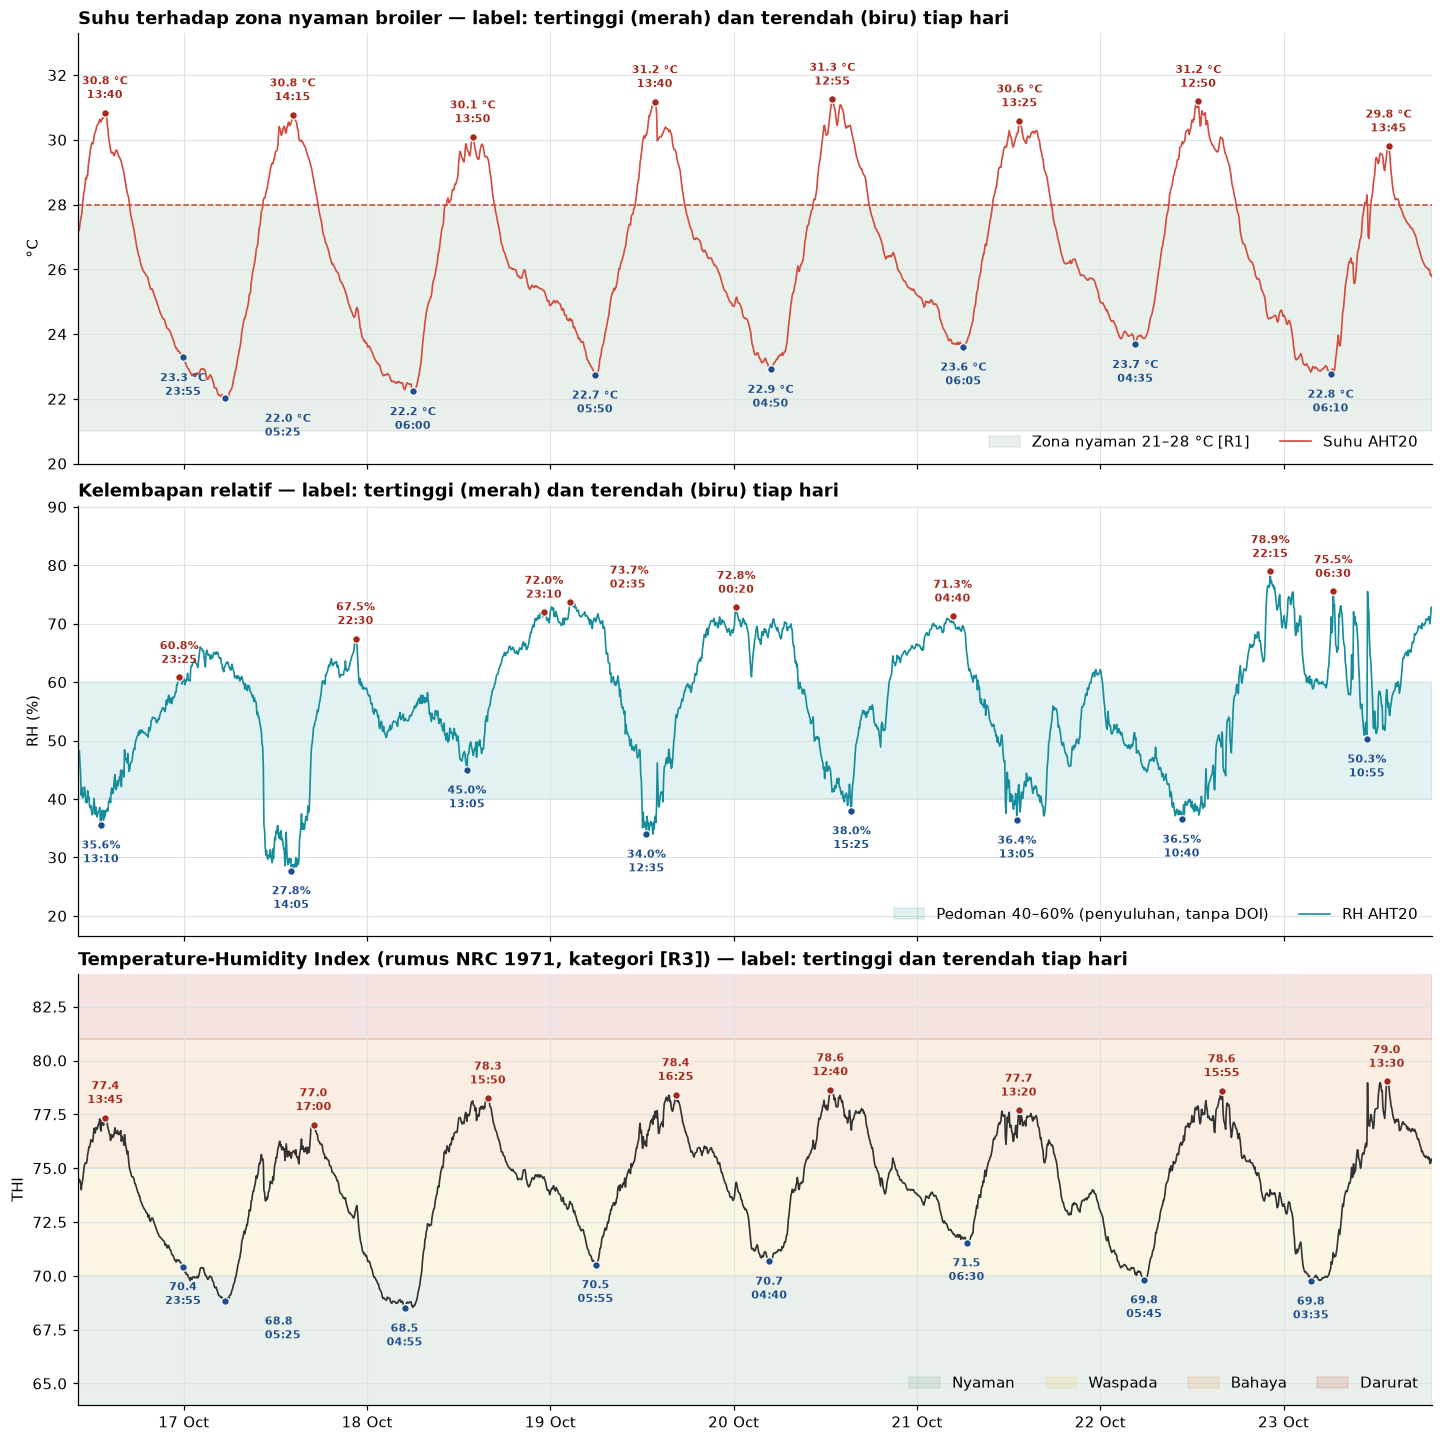

,Suhu (°C) maks,jam Suhu (°C) maks,Suhu (°C) min,jam Suhu (°C) min,RH (%) maks,jam RH (%) maks,RH (%) min,jam RH (%) min,THI maks,jam THI maks,THI min,jam THI min
16 Oct,30.8,13:40,23.3,23:55,60.8,23:25,35.6,13:10,77.4,13:45,70.4,23:55
17 Oct,30.8,14:15,22.0,05:25,67.5,22:30,27.8,14:05,77.0,17:00,68.8,05:25
18 Oct,30.1,13:50,22.2,06:00,72.0,23:10,45.0,13:05,78.3,15:50,68.5,04:55
19 Oct,31.2,13:40,22.7,05:50,73.7,02:35,34.0,12:35,78.4,16:25,70.5,05:55
20 Oct,31.3,12:55,22.9,04:50,72.8,00:20,38.0,15:25,78.6,12:40,70.7,04:40
21 Oct,30.6,13:25,23.6,06:05,71.3,04:40,36.4,13:05,77.7,13:20,71.5,06:30
22 Oct,31.2,12:50,23.7,04:35,78.9,22:15,36.5,10:40,78.6,15:55,69.8,05:45
23 Oct,29.8,13:45,22.8,06:10,75.5,06:30,50.3,10:55,79.0,13:30,69.8,03:35


,Kriteria,% waktu
0,Suhu di atas 28 °C,30.5
1,Suhu di zona 21–28 °C,69.5
2,Suhu di bawah 21 °C,0.0
3,RH di atas 60%,41.6
4,RH 40–60%,48.4
5,RH di bawah 40%,10.0
6,THI Nyaman,8.2
7,THI Waspada,49.6
8,THI Bahaya,42.2
9,THI Darurat,0.0


In [3]:
TN_LOW, TN_HIGH = 21.0, 28.0      # zona nyaman broiler [R1]
RH_LOW, RH_HIGH = 40.0, 60.0      # pedoman penyuluhan UGA (tanpa DOI)
THI_BANDS = [(-np.inf, 70, 'Nyaman', '#6f9e7a'), (70, 75, 'Waspada', '#e5c04a'),
             (75, 81, 'Bahaya', '#e08a3c'), (81, np.inf, 'Darurat', '#c2453a')]   # [R3]

def thi_nrc(t_c, rh):
    tf = 1.8 * t_c + 32
    return tf - (0.55 - 0.0055 * rh) * (tf - 58)

b['thi'] = thi_nrc(b.temp, b.rh)

fig, axs = plt.subplots(3, 1, figsize=(13, 13), sharex=True, layout='constrained')
ax = axs[0]
ax.axhspan(TN_LOW, TN_HIGH, color='#6f9e7a', alpha=.15, label=f'Zona nyaman {TN_LOW:.0f}–{TN_HIGH:.0f} °C [R1]')
ax.plot(b.index, b.temp, color='#d34c40', lw=1.1, label='Suhu AHT20')
ax.axhline(TN_HIGH, color='#c2453a', ls='--', lw=1)
mark_peaks_lows(ax, b.temp, ' °C')
ax.set_ylabel('°C'); ax.set_title('Suhu terhadap zona nyaman broiler — label: tertinggi (merah) dan terendah (biru) tiap hari', loc='left'); ax.legend(frameon=False, loc='lower right', ncol=2)
ax = axs[1]
ax.axhspan(RH_LOW, RH_HIGH, color='#168d9b', alpha=.12, label='Pedoman 40–60% (penyuluhan, tanpa DOI)')
ax.plot(b.index, b.rh, color='#168d9b', lw=1.1, label='RH AHT20')
mark_peaks_lows(ax, b.rh, '%')
ax.set_ylabel('RH (%)'); ax.set_title('Kelembapan relatif — label: tertinggi (merah) dan terendah (biru) tiap hari', loc='left'); ax.legend(frameon=False, loc='lower right', ncol=2)
ax = axs[2]
for lo, hi, name, col in THI_BANDS:
    ax.axhspan(max(lo, 60), min(hi, 90), color=col, alpha=.15, label=f'{name}')
ax.plot(b.index, b.thi, color='#333', lw=1.1)
mark_peaks_lows(ax, b.thi, '')
ax.set_ylim(64, 84); ax.set_ylabel('THI'); ax.set_title('Temperature-Humidity Index (rumus NRC 1971, kategori [R3]) — label: tertinggi dan terendah tiap hari', loc='left')
ax.legend(frameon=False, ncol=4, loc='lower right')
for ax in axs: time_axis(ax)
plt.show()

print('Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):')
display(extremes_table({'Suhu (°C)': (b.temp, 1), 'RH (%)': (b.rh, 1), 'THI': (b.thi, 1)}))

def share(mask): return 100 * mask.mean()
summary = pd.DataFrame({
    'Kriteria': ['Suhu di atas 28 °C', 'Suhu di zona 21–28 °C', 'Suhu di bawah 21 °C',
                 'RH di atas 60%', 'RH 40–60%', 'RH di bawah 40%'] + [f'THI {n}' for _, _, n, _ in THI_BANDS],
    '% waktu': [share(b.temp > TN_HIGH), share(b.temp.between(TN_LOW, TN_HIGH)), share(b.temp < TN_LOW),
                share(b.rh > RH_HIGH), share(b.rh.between(RH_LOW, RH_HIGH)), share(b.rh < RH_LOW)]
               + [share((b.thi >= lo) & (b.thi < hi)) for lo, hi, _, _ in THI_BANDS]})
summary['% waktu'] = summary['% waktu'].round(1)
summary

## 3A. Insight: kapan kondisi kandang kritis?

Bagian ini membaca data memakai **batas dari publikasi** (bukan garis statistik): suhu 28 °C sebagai batas atas zona nyaman broiler [R1], kategori THI [R3], dan RH 60% (pedoman penyuluhan). Heatmap hari × jam di bawah menunjukkan **pada jam berapa** setiap batas terlewati, dan profil per jam merangkum pola rata-rata seminggu.

Batas kategori THI di artikel [R3] tertulis 70–75 (waspada) dan 76–81 (bahaya), dengan celah antara 75 dan 76. Notebook ini memakai 75 sebagai awal kategori bahaya, pilihan yang lebih hati-hati.

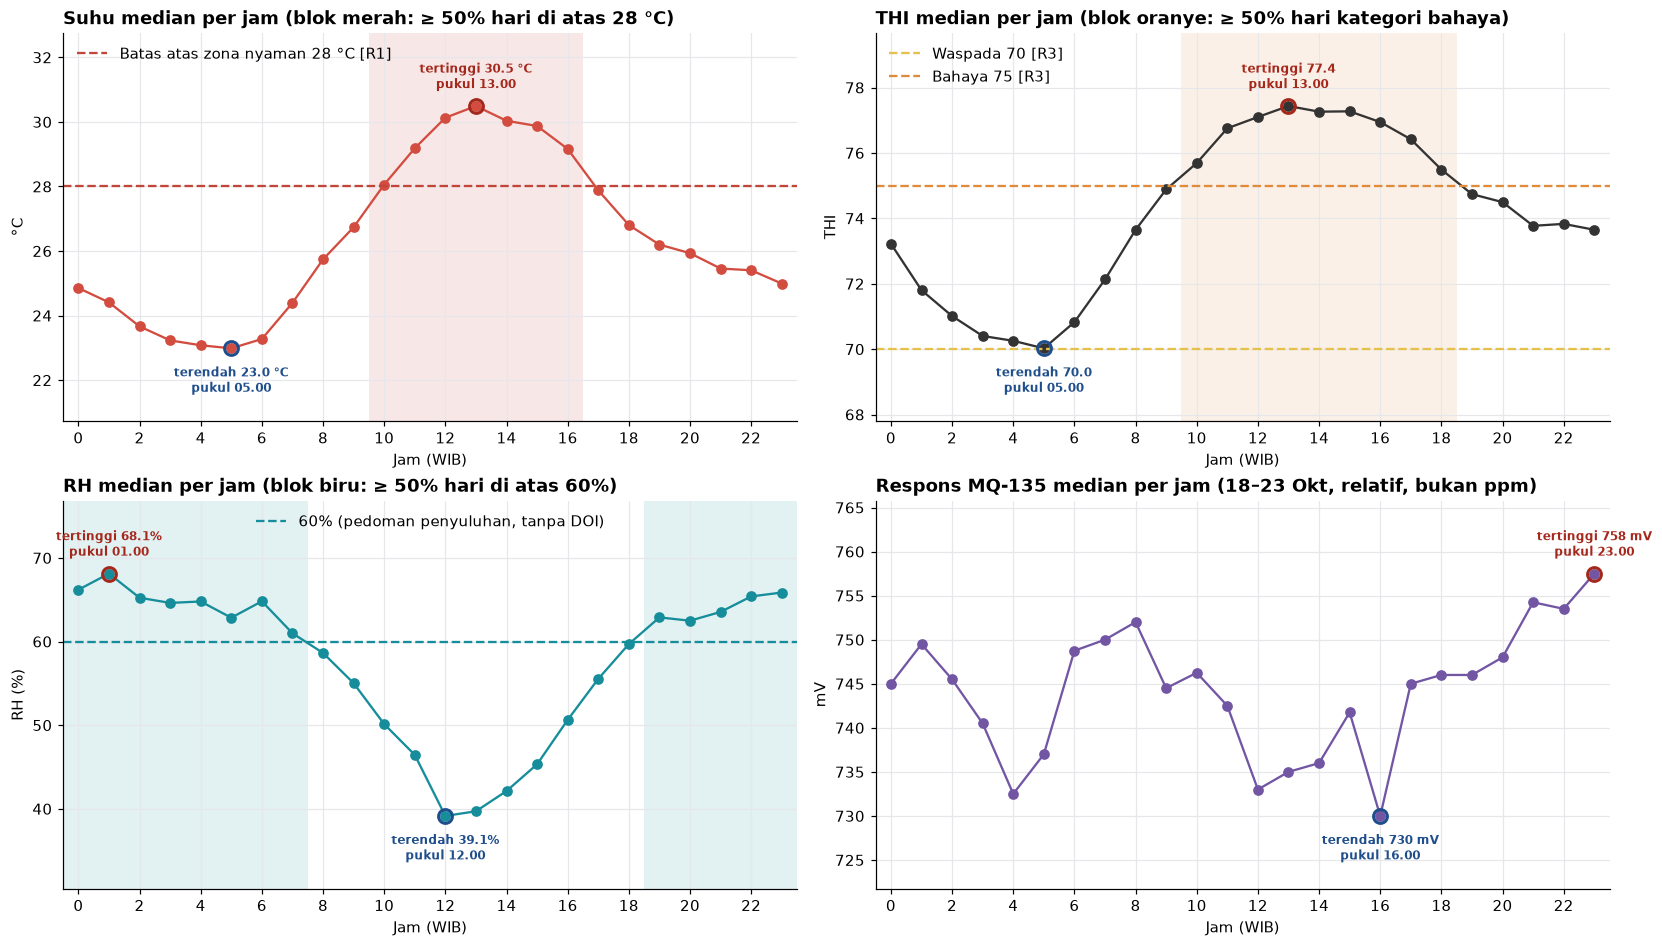

,suhu_median,pct_suhu_lebih_28,thi_median,pct_thi_bahaya,rh_median,pct_rh_lebih_60,mq_median_stabil
hour,,,,,,,
0,24.9,0.0,73.2,0.0,66.2,73.8,745.0
1,24.4,0.0,71.8,0.0,68.1,71.4,749.5
2,23.7,0.0,71.0,0.0,65.2,71.4,745.5
3,23.2,0.0,70.4,0.0,64.6,63.1,740.5
4,23.1,0.0,70.3,0.0,64.8,64.3,732.5
5,23.0,0.0,70.0,0.0,62.8,61.9,737.0
6,23.3,0.0,70.8,0.0,64.8,71.4,748.8
7,24.4,0.0,72.1,0.0,61.0,66.7,750.0
8,25.7,0.0,73.6,1.2,58.6,22.6,752.0


In [4]:
b['hour'] = b.index.hour
hourly = b.groupby('hour').agg(
    suhu_median=('temp', 'median'),
    pct_suhu_lebih_28=('temp', lambda s: 100 * (s > TN_HIGH).mean()),
    thi_median=('thi', 'median'),
    pct_thi_bahaya=('thi', lambda s: 100 * (s >= 75).mean()),
    rh_median=('rh', 'median'),
    pct_rh_lebih_60=('rh', lambda s: 100 * (s > RH_HIGH).mean()),
    mq_median_stabil=('mq', lambda s: s[s.index >= pd.Timestamp('2026-10-18', tz=TZ)].median()))

fig, axs = plt.subplots(2, 2, figsize=(15, 8.5), layout='constrained')
hrs = hourly.index
def shade_hours(ax, mask, color):
    for h in hrs[mask]:
        ax.axvspan(h - .5, h + .5, color=color, alpha=.12, lw=0)
ax = axs[0, 0]
shade_hours(ax, hourly.pct_suhu_lebih_28 >= 50, '#c2453a')
ax.plot(hrs, hourly.suhu_median, 'o-', color='#d34c40'); ax.axhline(TN_HIGH, color='#c2453a', ls='--', label='Batas atas zona nyaman 28 °C [R1]')
ax.set_title('Suhu median per jam (blok merah: ≥ 50% hari di atas 28 °C)', loc='left'); ax.set_ylabel('°C'); ax.legend(frameon=False)
ax = axs[0, 1]
shade_hours(ax, hourly.pct_thi_bahaya >= 50, '#e08a3c')
ax.plot(hrs, hourly.thi_median, 'o-', color='#333'); ax.axhline(70, color='#e5c04a', ls='--', label='Waspada 70 [R3]'); ax.axhline(75, color='#e08a3c', ls='--', label='Bahaya 75 [R3]')
ax.set_title('THI median per jam (blok oranye: ≥ 50% hari kategori bahaya)', loc='left'); ax.set_ylabel('THI'); ax.legend(frameon=False)
ax = axs[1, 0]
shade_hours(ax, hourly.pct_rh_lebih_60 >= 50, '#168d9b')
ax.plot(hrs, hourly.rh_median, 'o-', color='#168d9b'); ax.axhline(RH_HIGH, color='#168d9b', ls='--', label='60% (pedoman penyuluhan, tanpa DOI)')
ax.set_title('RH median per jam (blok biru: ≥ 50% hari di atas 60%)', loc='left'); ax.set_ylabel('RH (%)'); ax.legend(frameon=False)
ax = axs[1, 1]
ax.plot(hrs, hourly.mq_median_stabil, 'o-', color='#7256a4')
ax.set_title('Respons MQ-135 median per jam (18–23 Okt, relatif, bukan ppm)', loc='left'); ax.set_ylabel('mV')

def mark_hourly(ax, s, unit, dp=1):
    # Label jam dengan median tertinggi dan terendah
    lo, hi = s.min(), s.max(); span = hi - lo
    for h, above, col in [(s.idxmax(), True, '#a5281c'), (s.idxmin(), False, '#1f4e8c')]:
        v = s.loc[h]
        ax.plot(h, v, 'o', ms=9, mfc='none', mec=col, mew=2, zorder=5)
        ax.annotate(f'{"tertinggi" if above else "terendah"} {v:.{dp}f}{unit}\npukul {h:02d}.00', (h, v), textcoords='offset points',
                    xytext=(0, 9 if above else -11), ha='center', va='bottom' if above else 'top',
                    fontsize=8, color=col, fontweight='bold')
    ax.set_ylim(lo - .3 * span, hi + .3 * span)

mark_hourly(axs[0, 0], hourly.suhu_median, ' °C')
mark_hourly(axs[0, 1], hourly.thi_median, '')
mark_hourly(axs[1, 0], hourly.rh_median, '%')
mark_hourly(axs[1, 1], hourly.mq_median_stabil, ' mV', dp=0)
for ax in axs.ravel():
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Jam (WIB)'); ax.grid(True, color='#e5e7eb'); ax.set_xlim(-.5, 23.5)
plt.show()
hourly.round(1)

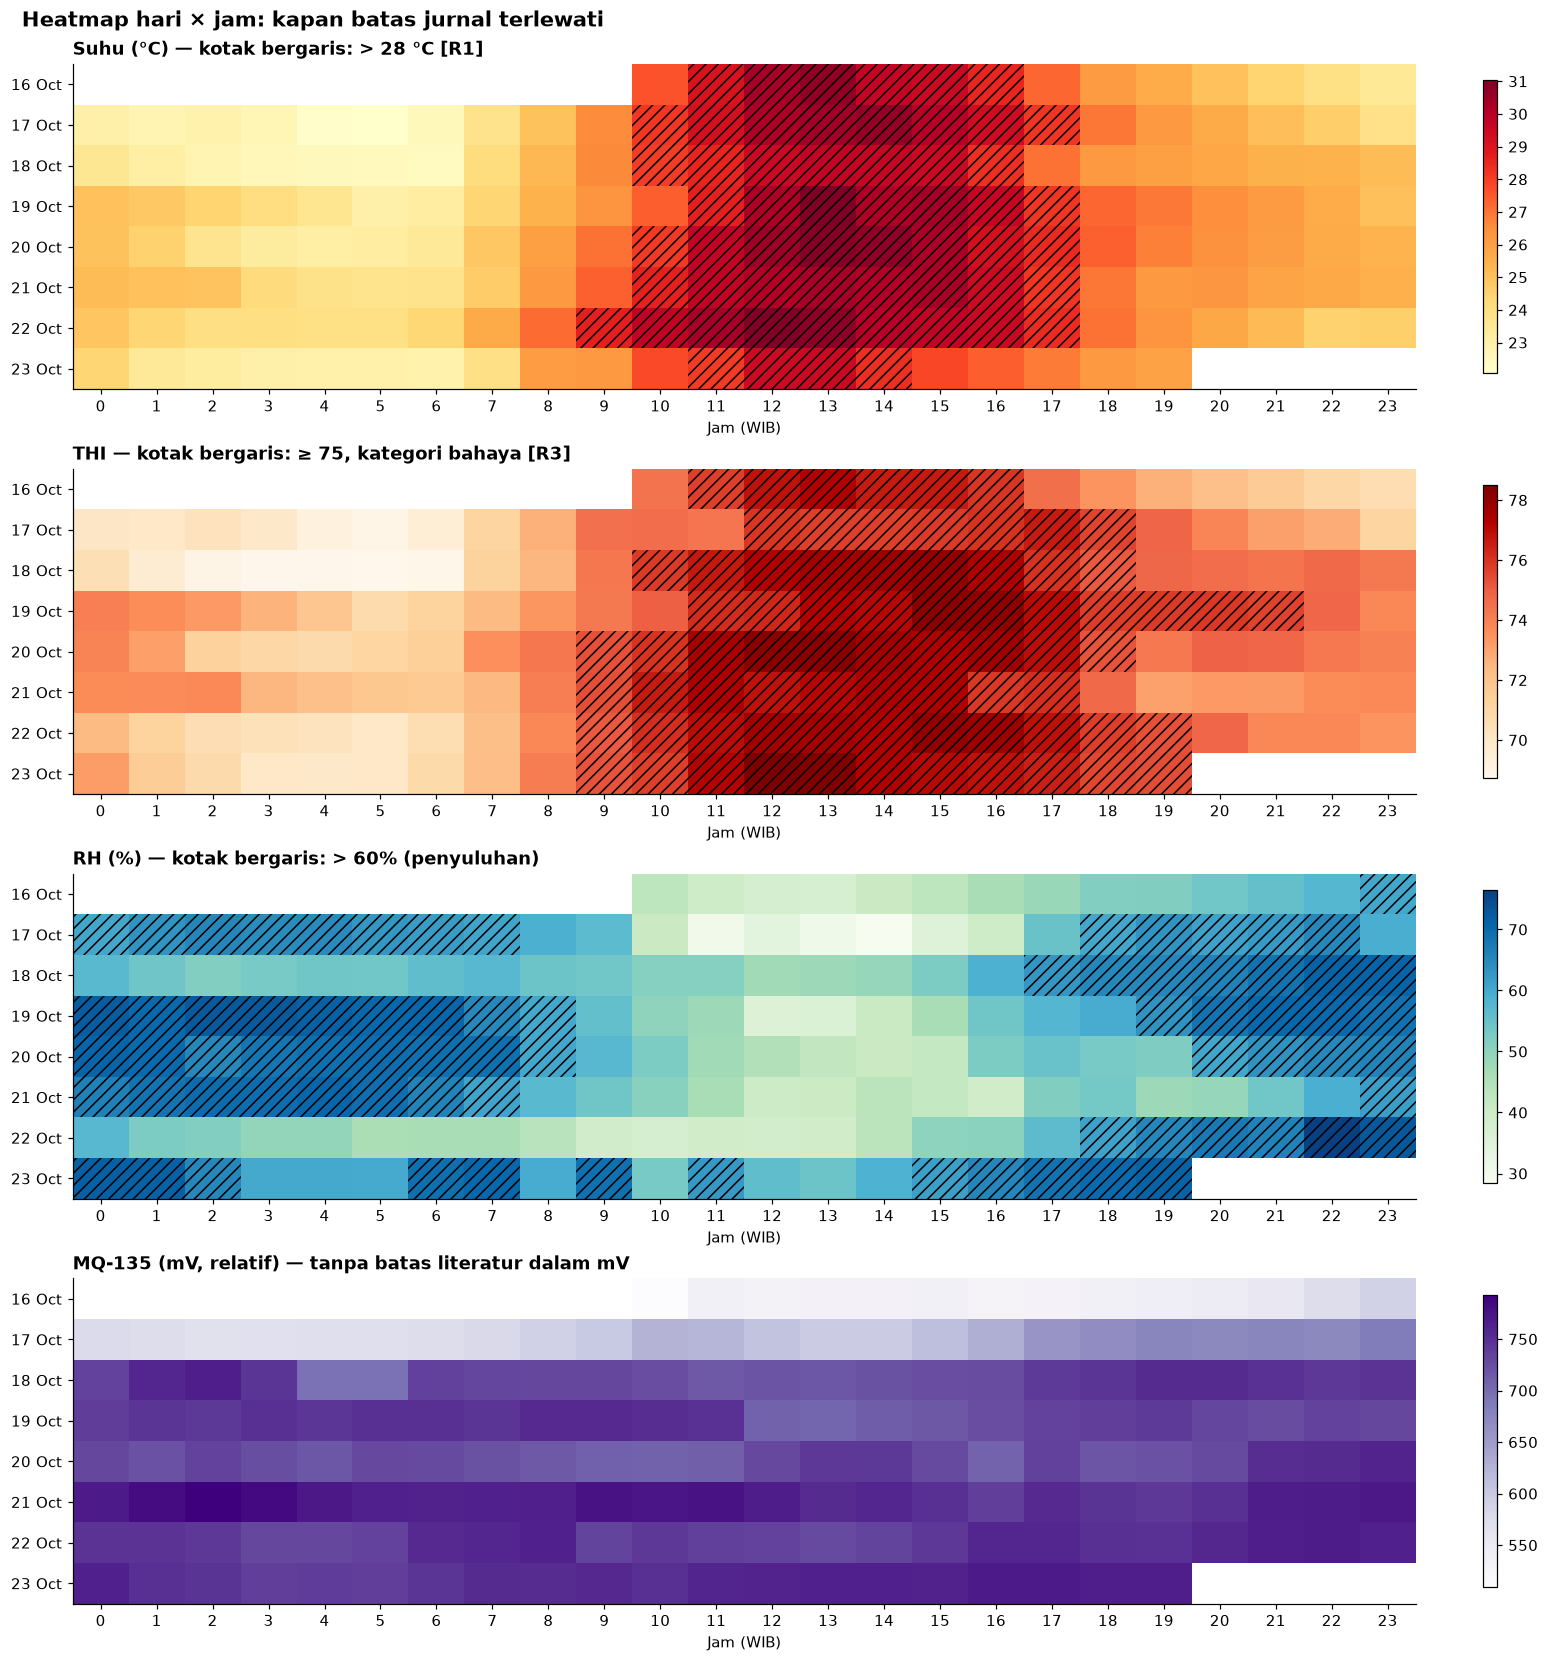

,jam suhu > 28 °C,jam THI ≥ 75,THI maksimum,jam RH > 60%,suhu maks (°C)
date,,,,,
2026-10-16,6.2,5.9,77.4,0.7,30.8
2026-10-17,7.2,8.2,77.0,12.5,30.8
2026-10-18,6.3,8.8,78.3,7.2,30.1
2026-10-19,6.5,11.8,78.4,13.8,31.2
2026-10-20,7.3,9.9,78.6,12.1,31.3
2026-10-21,7.8,9.2,77.7,9.1,30.6
2026-10-22,8.8,10.9,78.6,6.1,31.2
2026-10-23,4.0,10.1,79.0,12.4,29.8


In [5]:
def day_hour(col, agg='median'):
    t = b.assign(day=b.index.strftime('%d %b'), hour=b.index.hour)
    return t.pivot_table(index='day', columns='hour', values=col, aggfunc=agg).reindex(sorted(t['day'].unique(), key=lambda d: pd.Timestamp(d + ' 2026')))

panels = [('temp', 'Suhu (°C) — kotak bergaris: > 28 °C [R1]', 'YlOrRd', lambda v: v > TN_HIGH),
          ('thi', 'THI — kotak bergaris: ≥ 75, kategori bahaya [R3]', 'OrRd', lambda v: v >= 75),
          ('rh', 'RH (%) — kotak bergaris: > 60% (penyuluhan)', 'GnBu', lambda v: v > RH_HIGH),
          ('mq', 'MQ-135 (mV, relatif) — tanpa batas literatur dalam mV', 'Purples', None)]
fig, axs = plt.subplots(4, 1, figsize=(14, 15), layout='constrained')
for ax, (col, title, cmap, rule) in zip(axs, panels):
    M = day_hour(col)
    im = ax.imshow(M.values, aspect='auto', cmap=cmap)
    ax.set_yticks(range(len(M.index)), M.index); ax.set_xticks(range(0, 24), range(0, 24))
    ax.set_xlabel('Jam (WIB)'); ax.set_title(title, loc='left')
    fig.colorbar(im, ax=ax, shrink=.9)
    if rule is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M.values[i, j]
                if np.isfinite(v) and rule(v):
                    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch='///', edgecolor='black', lw=0))
fig.suptitle('Heatmap hari × jam: kapan batas jurnal terlewati', x=.01, ha='left', fontsize=14, fontweight='bold')
plt.show()

per_day = pd.DataFrame({
    'jam suhu > 28 °C': b.groupby('date').temp.apply(lambda s: (s > TN_HIGH).sum() * 5 / 60),
    'jam THI ≥ 75': b.groupby('date').thi.apply(lambda s: (s >= 75).sum() * 5 / 60),
    'THI maksimum': b.groupby('date').thi.max(),
    'jam RH > 60%': b.groupby('date').rh.apply(lambda s: (s > RH_HIGH).sum() * 5 / 60),
    'suhu maks (°C)': b.groupby('date').temp.max()}).round(1)
per_day

### Cerita data Minggu 1

**1. Setiap hari ada jendela stres panas pada siang hari.** Suhu kandang melewati 28 °C, batas atas zona nyaman broiler menurut Apalowo dkk. (2024) [R1], **setiap hari** dari kira-kira pukul 10.00 sampai 17.30 WIB, yaitu 6–9 jam per hari. Puncaknya 30–31 °C sekitar pukul 13.00–14.00. Antara pukul 12.00 dan 15.00, suhu berada di atas 28 °C pada **semua** hari yang terekam.

**2. THI menunjukkan risiko yang sama, dan lebih panjang.** Dengan kategori THI dari Kim dkk. (2024) [R3], kandang berada di kategori **bahaya** (THI ≥ 75) setiap siang pukul 12.00–16.00, dan sering juga pukul 10.00–18.00, yaitu sekitar 6–12 jam per hari. THI tidak pernah mencapai kategori darurat (maksimum 79,0 pada 23 Okt). Kim dkk. memakai kategori ini untuk menilai stres panas dalam penelitian performa bertelur, kualitas telur, dan respons fisiologis ayam petelur. Brugaletta dkk. (2022) [R2] menjelaskan sebabnya: kelembapan tinggi membatasi pelepasan panas lewat penguapan, sehingga ayam makin sulit mendinginkan tubuh.

**3. Malam hari punya risiko lain: udara lembap.** Dari pukul 19.00 sampai 07.00, RH berada di atas 60% pada sebagian besar hari (median 62–68%, mencapai 79% saat hujan 23 Okt). Pedoman penyuluhan menyebut RH di atas 60% sering berarti litter basah dan kualitas udara buruk. Kadar air litter tidak diukur di kandang ini, jadi kaitan antara malam yang lembap dan amonia masih berupa dugaan yang perlu dicek.

**4. Respons gas MQ-135 tinggi pada jam yang berbeda dari jam panas.** Pada periode stabil (18–23 Okt), median MQ paling rendah pada siang hari (730–736 mV) dan paling tinggi pada malam hari pukul 21.00–02.00 (745–758 mV) serta pagi pukul 06.00–08.00. Korelasi THI dengan MQ hampir nol (r ≈ −0,03). Artinya **ada dua jendela risiko terpisah**:
- **siang**: stres panas (suhu dan THI di atas batas jurnal),
- **malam sampai pagi**: udara lembap dan respons gas relatif tinggi.

Sebagian kenaikan MQ pada malam hari dijelaskan oleh kelembapan itu sendiri (sekitar +0,6 mV per poin RH, lihat bagian 4), karena sensor oksida logam ikut bereaksi pada uap air [R5]. Jadi nilai MQ yang tinggi pada malam yang lembap **belum tentu** berarti amonia lebih tinggi.

**5. Mulai 21 Oktober, respons gas bergeser naik.** Pada 21 Okt respons MQ berada di atas 754 mV selama sekitar 18 jam, dibanding kurang dari 5 jam per hari pada 18–20 Okt. Satu-satunya laporan bau menyengat (akhir 23 Okt) juga terjadi pada periode tinggi ini. Penyebabnya (misalnya penumpukan litter) tidak terukur di data ini.

**6. Tentang garis ambang MQ (695,5 / 729 / 754 mV).** Garis-garis ini **bukan** batas dari jurnal. Untuk sensor MQ-135 yang belum dikalibrasi, tidak ada publikasi yang bisa memberi batas dalam mV, karena satuannya bergantung pada rangkaian dan modul. Batas 25 ppm amonia [R4] hanya bisa dipakai setelah sensor dikalibrasi terhadap alat ukur amonia. Karena itu, garis 729 dan 754 mV dibaca sebagai: "respons gas lebih tinggi dari biasanya untuk modul ini", bukan "amonia berbahaya".

**Rekomendasi pemantauan:**
- Siang (10.00–17.30): fokus pada suhu dan THI; ventilasi atau pendinginan adalah prioritas.
- Malam sampai pagi (19.00–08.00): fokus pada kelembapan dan respons gas; kalibrasi MQ-135 terhadap alat ukur amonia supaya batas 25 ppm [R4] bisa dipakai.

**Catatan amonia.** Batas 25 ppm [R4] tidak digambar di plot MQ-135 karena satuan sensor (mV) tidak bisa diubah ke ppm tanpa kalibrasi dengan alat ukur amonia referensi. Sensor MQ-135 juga bereaksi pada beberapa gas sekaligus (NH₃, CO₂, alkohol, benzena) dan dipengaruhi kelembapan [R5], jadi nilai mV hanya menunjukkan **kenaikan atau penurunan relatif**.

## 4. Korelasi antar variabel

Plot sebar (*scatter*) di bawah memakai pola yang sama dengan gambar acuan korelasi: setiap titik adalah satu median 5 menit, garis hitam adalah regresi linier (kuadrat terkecil), dan judul memuat koefisien korelasi Pearson *r* beserta kategorinya.

Kategori kekuatan berdasarkan |*r*|: < 0,1 tidak ada; 0,1–0,3 lemah; 0,3–0,5 sedang; ≥ 0,5 kuat. Tanda *r* menunjukkan arah (positif atau negatif).

**Peringatan metode:** semua variabel ini naik-turun mengikuti siklus siang–malam, jadi korelasi biasa bisa tercampur efek waktu (*confounding*), dan p-value biasa terlalu kecil karena data berurutan saling bergantung (*autokorelasi*). Karena itu bagian 4.3 juga memakai **selisih 30 menit** (*first differences*) dengan uji permutasi geser-sirkular.

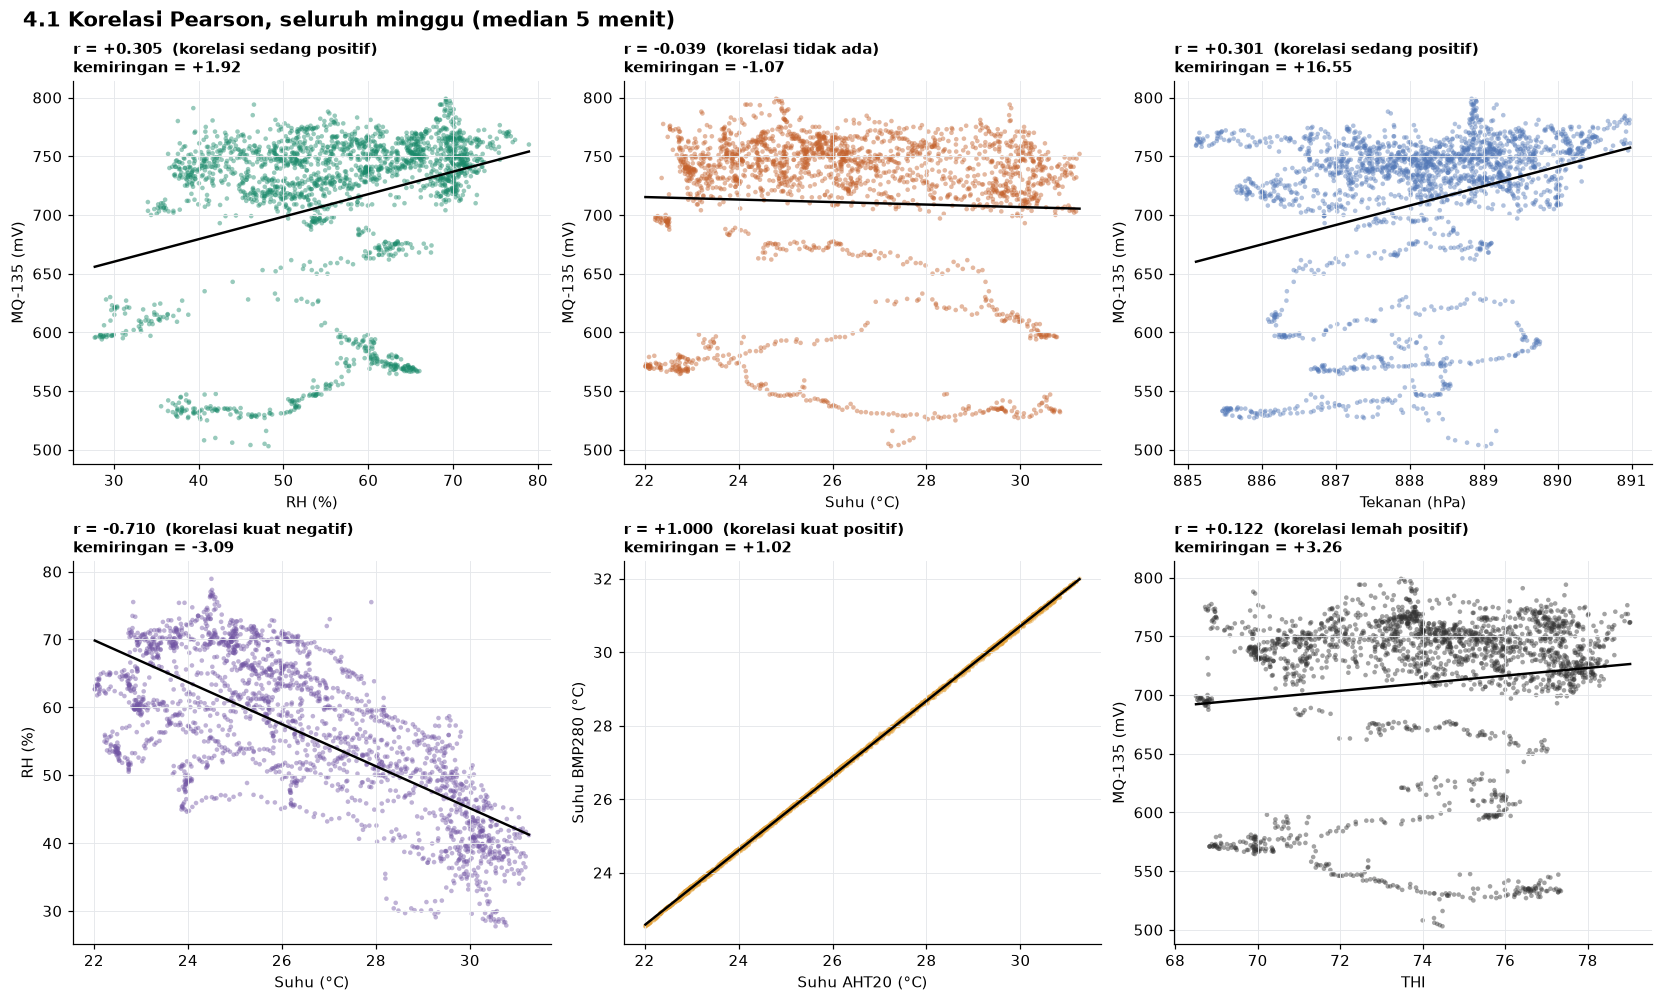

In [6]:
def strength(r):
    a = abs(r)
    lvl = 'tidak ada' if a < .1 else 'lemah' if a < .3 else 'sedang' if a < .5 else 'kuat'
    arah = '' if a < .1 else (' positif' if r > 0 else ' negatif')
    return f'korelasi {lvl}{arah}'

def scatter_r(ax, x, y, xl, yl, color):
    ok = x.notna() & y.notna(); x, y = x[ok], y[ok]
    r = np.corrcoef(x, y)[0, 1]
    m, c = np.polyfit(x, y, 1)
    ax.scatter(x, y, s=9, color=color, alpha=.45, edgecolors='none')
    xs = np.linspace(x.min(), x.max(), 50); ax.plot(xs, m * xs + c, color='black', lw=1.6)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f'r = {r:+.3f}  ({strength(r)})\nkemiringan = {m:+.2f}', loc='left', fontsize=10)
    ax.grid(True, color='#e5e7eb', lw=.6)
    return r

pairs = [('rh', 'mq', 'RH (%)', 'MQ-135 (mV)', '#1b8a6b'),
         ('temp', 'mq', 'Suhu (°C)', 'MQ-135 (mV)', '#c4622d'),
         ('press', 'mq', 'Tekanan (hPa)', 'MQ-135 (mV)', '#5278b7'),
         ('temp', 'rh', 'Suhu (°C)', 'RH (%)', '#7256a4'),
         ('temp', 'temp_bmp', 'Suhu AHT20 (°C)', 'Suhu BMP280 (°C)', '#e4a33c'),
         ('thi', 'mq', 'THI', 'MQ-135 (mV)', '#333333')]
fig, axs = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for ax, (xk, yk, xl, yl, col) in zip(axs.ravel(), pairs):
    scatter_r(ax, b[xk], b[yk], xl, yl, col)
fig.suptitle('4.1 Korelasi Pearson, seluruh minggu (median 5 menit)', x=.01, ha='left', fontsize=14, fontweight='bold')
plt.show()

### 4.2 Matriks korelasi

Kiri: korelasi seluruh minggu. Tengah: korelasi **dalam hari yang sama** (rata-rata setiap hari dikurangkan dulu, sehingga perbedaan antarhari hilang). Kanan: korelasi **selisih 30 menit**, yang paling sedikit terpengaruh siklus harian.

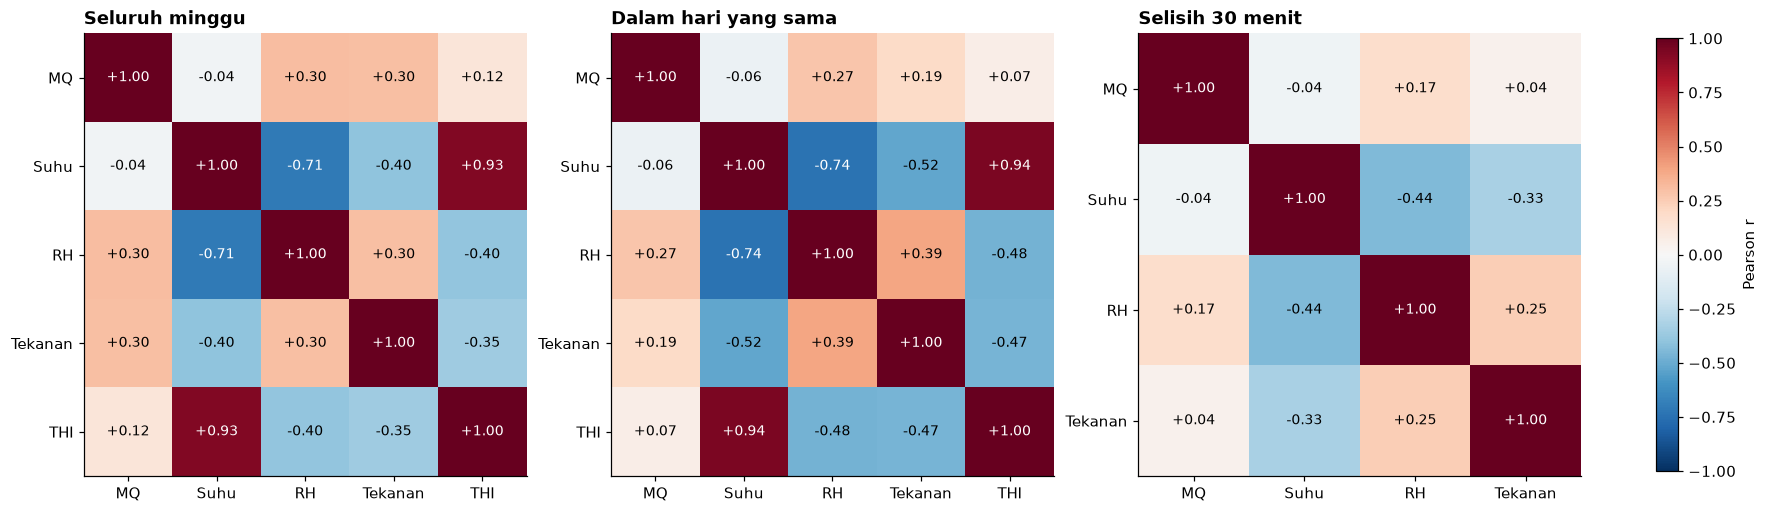

In [7]:
VARS = ['mq', 'temp', 'rh', 'press', 'thi']
LABELS = ['MQ', 'Suhu', 'RH', 'Tekanan', 'THI']
dc = b[VARS] - b.groupby('date')[VARS].transform('mean')
m1 = df.set_index('t')[['mq', 'temp', 'rh', 'press']].resample('1min').median()
d30 = m1.resample('30min').median().diff().dropna()
d30['thi'] = np.nan  # THI tidak dihitung untuk selisih
mats = [b[VARS].corr(), dc[VARS].corr(), d30[['mq', 'temp', 'rh', 'press']].corr()]
titles = ['Seluruh minggu', 'Dalam hari yang sama', 'Selisih 30 menit']
fig, axs = plt.subplots(1, 3, figsize=(16, 5), layout='constrained')
for ax, M, t in zip(axs, mats, titles):
    im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1, vmax=1)
    lab = [LABELS[VARS.index(c)] for c in M.columns]
    ax.set_xticks(range(len(lab)), lab); ax.set_yticks(range(len(lab)), lab)
    for i in range(len(lab)):
        for j in range(len(lab)):
            v = M.values[i, j]
            ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=9, color='white' if abs(v) > .6 else 'black')
    ax.set_title(t, loc='left')
fig.colorbar(im, ax=axs, shrink=.8, label='Pearson r')
plt.show()

### 4.3 Selisih 30 menit dengan uji permutasi

Untuk setiap setengah jam dihitung perubahan MQ, RH, dan suhu terhadap setengah jam sebelumnya. Signifikansi dihitung dengan **uji permutasi geser-sirkular**: deret RH (atau suhu) digeser minimal 6 jam sebanyak 5.000 kali, lalu p-value adalah proporsi geseran yang menghasilkan |*r*| sebesar atau lebih besar dari *r* asli. Cara ini mempertahankan struktur deret waktu, sehingga tidak terlalu optimistis seperti p-value biasa.

rh   : r = +0.175, p = 0.0002
temp : r = -0.044, p = 0.3467


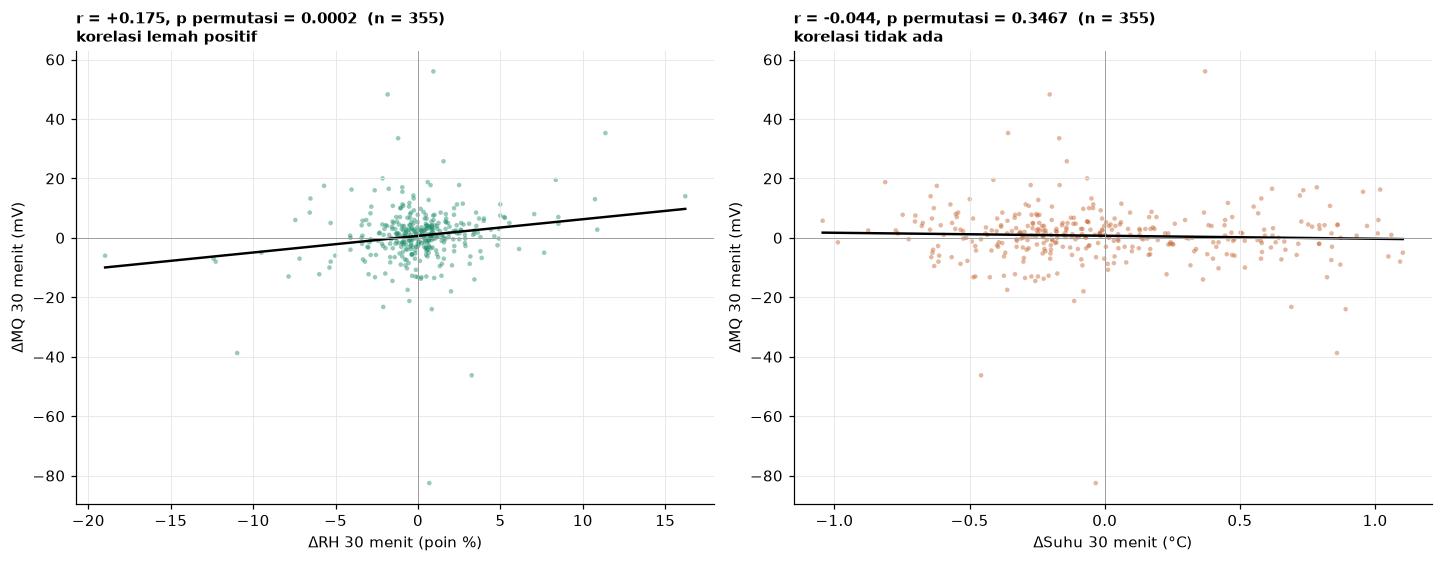

In [8]:
rng = np.random.default_rng(20261110)
def perm_p(a, c, n=5000, min_shift=12):     # 12 x 30 menit = 6 jam
    r0 = np.corrcoef(a, c)[0, 1]
    shifts = rng.integers(min_shift, len(a) - min_shift, n)
    null = np.array([np.corrcoef(a, np.roll(c, s))[0, 1] for s in shifts])
    return r0, ((np.abs(null) >= abs(r0)).sum() + 1) / (n + 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, (k, xl, col) in zip(axs, [('rh', 'ΔRH 30 menit (poin %)', '#1b8a6b'), ('temp', 'ΔSuhu 30 menit (°C)', '#c4622d')]):
    r, p = perm_p(d30.mq.values, d30[k].values)
    scatter_r(ax, d30[k], d30.mq, xl, 'ΔMQ 30 menit (mV)', col)
    ax.set_title(f'r = {r:+.3f}, p permutasi = {p:.4f}  (n = {len(d30)})\n{strength(r)}', loc='left', fontsize=10)
    ax.axhline(0, color='#999', lw=.6); ax.axvline(0, color='#999', lw=.6)
    print(f'{k:5s}: r = {r:+.3f}, p = {p:.4f}')
plt.show()

### 4.4 Korelasi per hari (uji tanda)

Korelasi MQ–RH dan MQ–suhu dihitung terpisah untuk setiap hari. Jika RH memang memengaruhi MQ, korelasinya seharusnya positif hampir setiap hari. Uji tanda binomial menguji apakah jumlah hari positif lebih banyak dari yang diharapkan secara kebetulan (50:50).

RH: positif 8 dari 8 hari, p uji tanda = 0.008
Suhu: positif 2 dari 8 hari, p uji tanda = 0.289


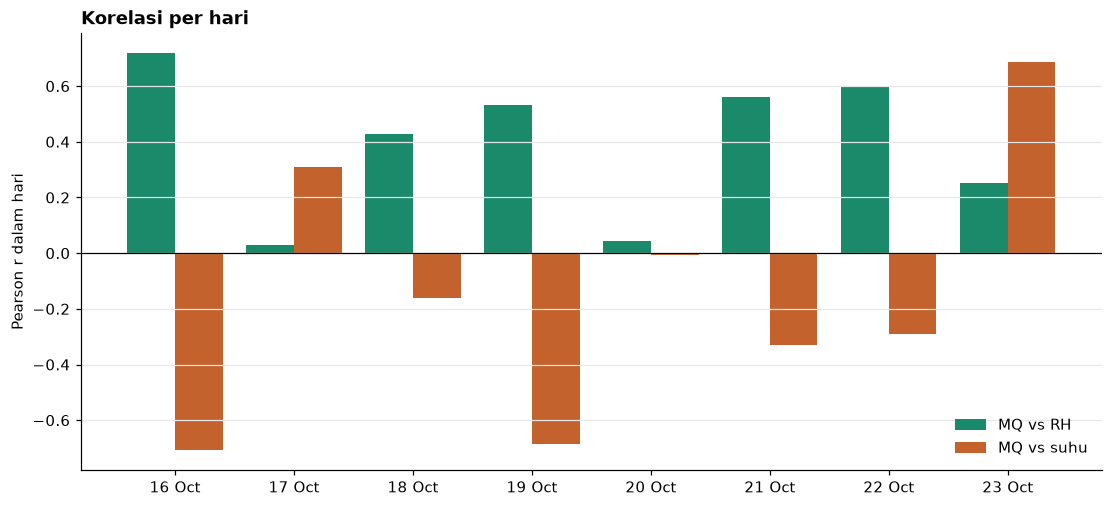

In [9]:
from math import comb
def sign_test(k, n):
    p = sum(comb(n, i) for i in range(n + 1) if comb(n, i) <= comb(n, k)) / 2 ** n
    return min(1.0, p)

daily = pd.DataFrame({v: {d: np.corrcoef(gr.mq, gr[v])[0, 1] for d, gr in b.groupby('date')} for v in ['rh', 'temp']})
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
x = np.arange(len(daily))
ax.bar(x - .2, daily.rh, .4, color='#1b8a6b', label='MQ vs RH')
ax.bar(x + .2, daily.temp, .4, color='#c4622d', label='MQ vs suhu')
ax.axhline(0, color='black', lw=.8)
ax.set_xticks(x, [pd.Timestamp(d).strftime('%d %b') for d in daily.index]); ax.set_ylabel('Pearson r dalam hari')
ax.legend(frameon=False); ax.grid(True, axis='y', color='#e5e7eb')
for v, name in [('rh', 'RH'), ('temp', 'Suhu')]:
    k = int((daily[v] > 0).sum())
    print(f'{name}: positif {k} dari {len(daily)} hari, p uji tanda = {sign_test(k, len(daily)):.3f}')
ax.set_title('Korelasi per hari', loc='left')
plt.show()

## 5. Plot 3 dimensi

Plot 3D menampilkan tiga variabel sekaligus: suhu (sumbu X), RH (sumbu Y), dan respons MQ-135 (sumbu Z).

- **5.1** setiap bola adalah satu median 5 menit; warna dan ukuran bola mengikuti nilai MQ.
- **5.2** titik yang sama, diwarnai menurut status hasil *clustering* (Normal, Elevated, High).
- **5.3** bidang regresi berganda MQ = b₀ + b₁·Suhu + b₂·RH, yang memisahkan efek suhu dari efek RH.
- **5.4** permukaan rata-rata MQ untuk setiap kotak suhu × RH.

Agar tidak terlalu padat, plot 3D memakai median 30 menit (sekitar 350 titik). Periode awal pemanasan sensor (sebelum 18 Oktober) dibuang karena nilainya masih naik terus tanpa kaitan dengan suhu/RH.

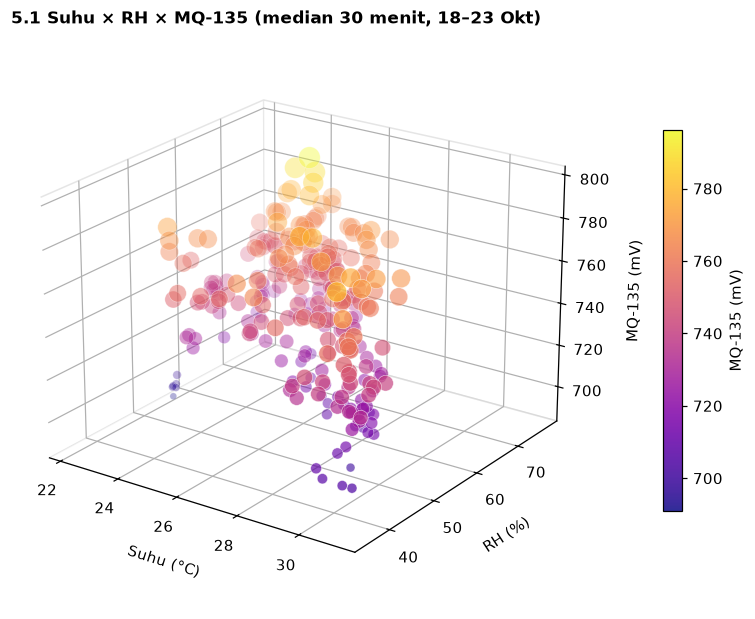

In [10]:
settled = b[b.index >= pd.Timestamp('2026-10-18', tz=TZ)]
s30 = settled[['mq', 'temp', 'rh']].resample('30min').median().dropna()

def style3d(ax, title):
    ax.set_xlabel('Suhu (°C)', labelpad=8); ax.set_ylabel('RH (%)', labelpad=8); ax.set_zlabel('MQ-135 (mV)', labelpad=8)
    ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor((1, 1, 1, 0)); axis.pane.set_edgecolor('#cccccc')
    ax.view_init(elev=22, azim=-55)

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
size = 20 + 180 * (s30.mq - s30.mq.min()) / (s30.mq.max() - s30.mq.min())
sc = ax.scatter(s30.temp, s30.rh, s30.mq, c=s30.mq, s=size, cmap='plasma', alpha=.85,
                edgecolors='white', linewidths=.4, depthshade=True)
fig.colorbar(sc, ax=ax, shrink=.6, pad=.1, label='MQ-135 (mV)')
style3d(ax, '5.1 Suhu × RH × MQ-135 (median 30 menit, 18–23 Okt)')
plt.show()

Pusat cluster (mV): [716.5 742.3 765.1]  | batas: [729.4 753.7]


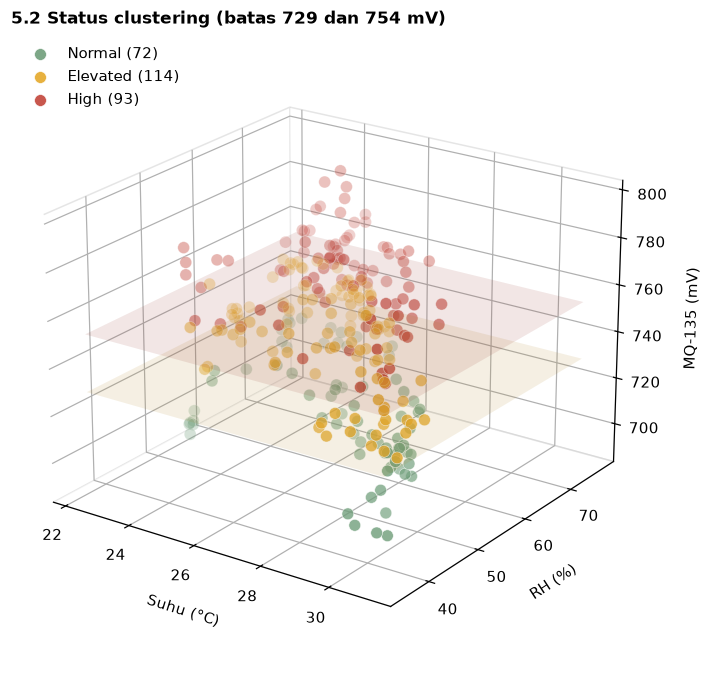

In [11]:
from sklearn.cluster import KMeans
km = KMeans(3, n_init=20, random_state=0).fit(settled[['mq']].values)
centres = np.sort(km.cluster_centers_.ravel())
bounds = (centres[:-1] + centres[1:]) / 2
print('Pusat cluster (mV):', centres.round(1), ' | batas:', bounds.round(1))

state_names = np.array(['Normal', 'Elevated', 'High'])
state_cols = {'Normal': '#6f9e7a', 'Elevated': '#e5a92a', 'High': '#c2453a'}
s30['state'] = state_names[np.digitize(s30.mq, bounds)]

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
for st in state_names:
    q = s30[s30.state == st]
    ax.scatter(q.temp, q.rh, q.mq, s=60, color=state_cols[st], label=f'{st} ({len(q)})',
               edgecolors='white', linewidths=.4, alpha=.9, depthshade=True)
# bidang ambang peringatan
tt, hh = np.meshgrid(np.linspace(s30.temp.min(), s30.temp.max(), 2), np.linspace(s30.rh.min(), s30.rh.max(), 2))
for bd, col in zip(bounds, ['#e5a92a', '#c2453a']):
    ax.plot_surface(tt, hh, np.full_like(tt, bd), color=col, alpha=.12, edgecolor='none')
ax.legend(frameon=False, loc='upper left')
style3d(ax, f'5.2 Status clustering (batas {bounds[0]:.0f} dan {bounds[1]:.0f} mV)')
plt.show()

MQ = 688.8 +0.70·Suhu +0.63·RH   (R² = 0.077, n = 279)
Catatan: ini regresi pada median 30 menit seluruh periode 18–23 Okt. Analisis utama (laporan 10 Nov)
memakai regresi dalam-hari dengan interval kepercayaan bootstrap per hari.


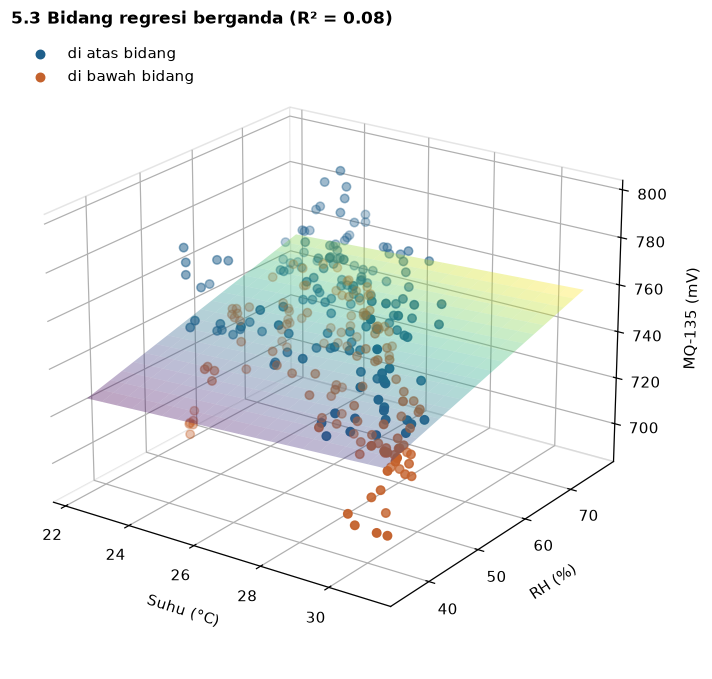

In [12]:
X = np.column_stack([np.ones(len(s30)), s30.temp, s30.rh])
beta, *_ = np.linalg.lstsq(X, s30.mq.values, rcond=None)
pred = X @ beta
r2 = 1 - ((s30.mq - pred) ** 2).sum() / ((s30.mq - s30.mq.mean()) ** 2).sum()
print(f'MQ = {beta[0]:.1f} {beta[1]:+.2f}·Suhu {beta[2]:+.2f}·RH   (R² = {r2:.3f}, n = {len(s30)})')
print('Catatan: ini regresi pada median 30 menit seluruh periode 18–23 Okt. Analisis utama (laporan 10 Nov)')
print('memakai regresi dalam-hari dengan interval kepercayaan bootstrap per hari.')

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
tg, hg = np.meshgrid(np.linspace(s30.temp.min(), s30.temp.max(), 20), np.linspace(s30.rh.min(), s30.rh.max(), 20))
ax.plot_surface(tg, hg, beta[0] + beta[1] * tg + beta[2] * hg, cmap='viridis', alpha=.35, edgecolor='none')
above = s30.mq >= pred
ax.scatter(s30.temp[above], s30.rh[above], s30.mq[above], s=30, color='#1f5f8b', label='di atas bidang', depthshade=True)
ax.scatter(s30.temp[~above], s30.rh[~above], s30.mq[~above], s=30, color='#c4622d', label='di bawah bidang', depthshade=True)
ax.legend(frameon=False, loc='upper left')
style3d(ax, f'5.3 Bidang regresi berganda (R² = {r2:.2f})')
plt.show()

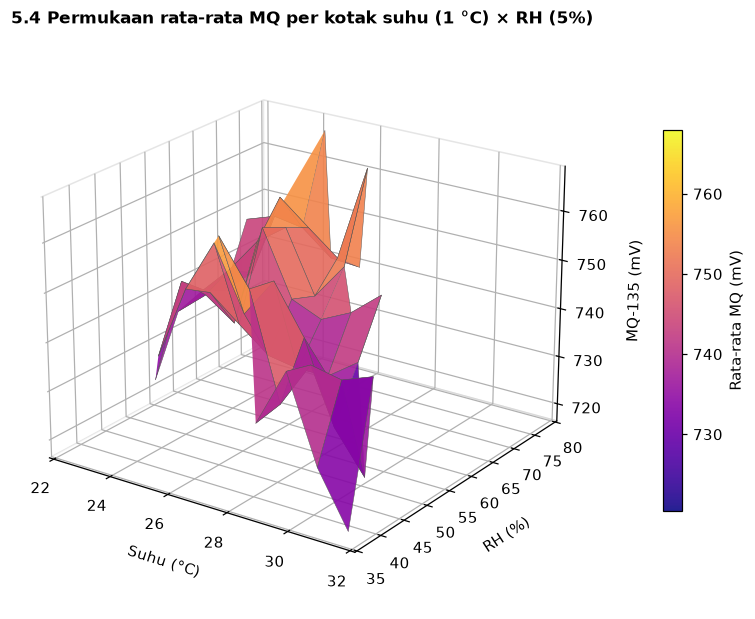

In [13]:
grid = settled.assign(tb=np.floor(settled.temp), hb=(np.floor(settled.rh / 5) * 5))
pivot = grid.groupby(['tb', 'hb']).mq.agg(['mean', 'count']).reset_index()
pivot = pivot[pivot['count'] >= 5]
P = pivot.pivot(index='hb', columns='tb', values='mean')
T, H = np.meshgrid(P.columns.values + .5, P.index.values + 2.5)
Z = np.ma.masked_invalid(P.values)

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
surf = ax.plot_surface(T, H, Z, cmap='plasma', edgecolor='#555', linewidth=.3, alpha=.9)
fig.colorbar(surf, ax=ax, shrink=.6, pad=.1, label='Rata-rata MQ (mV)')
style3d(ax, '5.4 Permukaan rata-rata MQ per kotak suhu (1 °C) × RH (5%)')
plt.show()

## 6. Ambang peringatan dari clustering

Ambang dipilih dengan **k-means 1 dimensi** pada median 5 menit periode stabil (18–23 Okt), k = 3. Batas antarstatus adalah titik tengah antara dua pusat cluster yang berdekatan. Jumlah cluster diperiksa dengan *silhouette score*: makin tinggi, makin terpisah kelompoknya.

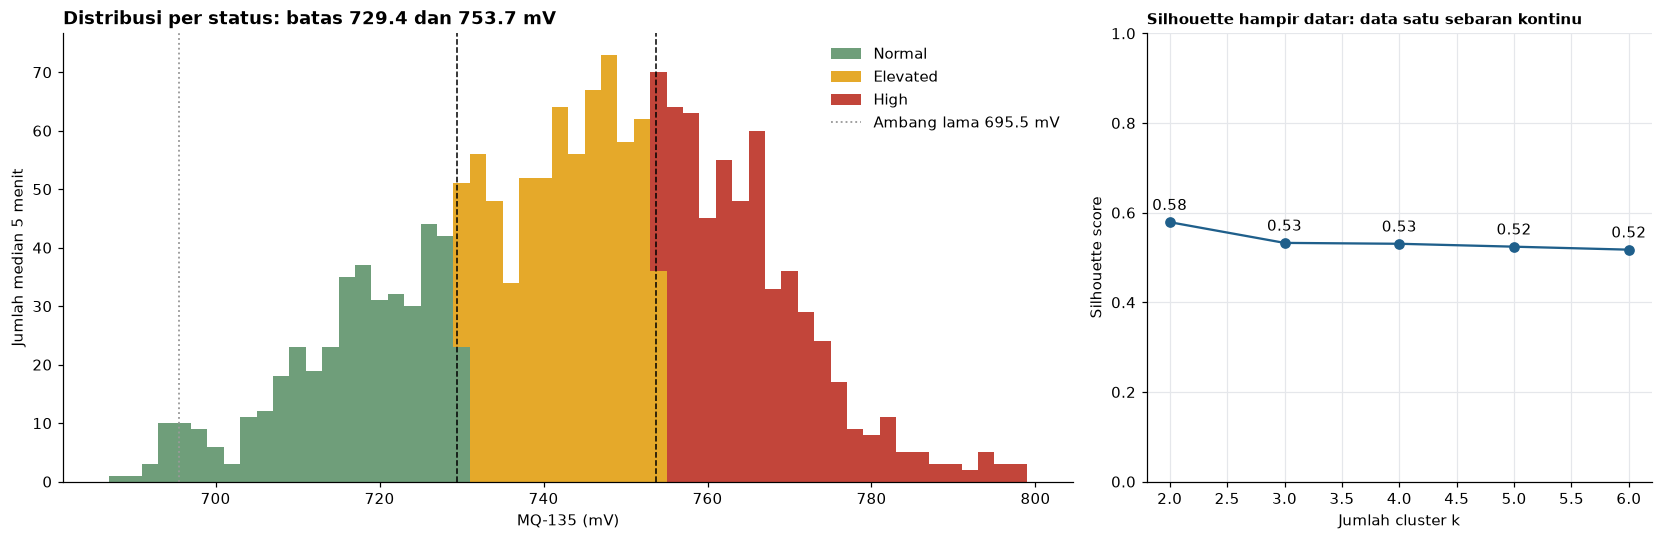

,Ambang,mV,% waktu di atas (18–23 Okt)
0,Ambang perangkat (lama),695.5,98.7
1,Watch (Normal/Elevated),729.4,74.7
2,Peringatan (Elevated/High),753.7,33.8


In [14]:
from sklearn.metrics import silhouette_score
Xs = settled[['mq']].values
ks, sil = range(2, 7), []
for k in ks:
    lab = KMeans(k, n_init=20, random_state=0).fit_predict(Xs)
    sil.append(silhouette_score(Xs, lab))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), layout='constrained', gridspec_kw={'width_ratios': [2, 1]})
ax = axs[0]
binsv = np.arange(np.floor(settled.mq.min()), settled.mq.max() + 2, 2)
lab3 = state_names[np.digitize(settled.mq, bounds)]
ax.hist([settled.mq[lab3 == s] for s in state_names], bins=binsv, stacked=True,
        color=[state_cols[s] for s in state_names], label=list(state_names))
for bd in bounds: ax.axvline(bd, color='black', ls='--', lw=1)
ax.axvline(device_thr, color='#999', ls=':', lw=1.2, label=f'Ambang lama {device_thr:.1f} mV')
ax.set_xlabel('MQ-135 (mV)'); ax.set_ylabel('Jumlah median 5 menit'); ax.legend(frameon=False)
ax.set_title(f'Distribusi per status: batas {bounds[0]:.1f} dan {bounds[1]:.1f} mV', loc='left')
ax = axs[1]
ax.plot(list(ks), sil, 'o-', color='#1f5f8b'); ax.set_ylim(0, 1)
ax.set_xlabel('Jumlah cluster k'); ax.set_ylabel('Silhouette score'); ax.grid(True, color='#e5e7eb')
ax.set_title('Silhouette hampir datar: data satu sebaran kontinu', loc='left', fontsize=10)
for k, s in zip(ks, sil): ax.annotate(f'{s:.2f}', (k, s), textcoords='offset points', xytext=(0, 8), ha='center')
plt.show()

above = pd.DataFrame({'Ambang': ['Ambang perangkat (lama)', 'Watch (Normal/Elevated)', 'Peringatan (Elevated/High)'],
                      'mV': [round(device_thr, 1), round(bounds[0], 1), round(bounds[1], 1)]})
above['% waktu di atas (18–23 Okt)'] = [round(100 * (settled.mq >= v).mean(), 1) for v in above['mV']]
above

## 7. Dashboard interaktif (Gradio)

Sel pertama di bawah menyiapkan fungsi-fungsi plot untuk dashboard dan langsung menampilkan contoh hasilnya, jadi bisa diperiksa tanpa Gradio. Sel kedua membuat dashboard Gradio dan menjalankannya di dalam notebook.

Gradio perlu dipasang sekali di environment Jupyter:

```
pip install gradio
```

Isi dashboard:
- **Deret waktu**: pilih variabel dan rentang tanggal; batas dari jurnal digambar sebagai pita berwarna.
- **Jam kritis**: heatmap hari × jam untuk variabel pilihan, dengan kotak bergaris saat batas jurnal terlewati.
- **3D**: suhu × RH × MQ-135, diwarnai THI atau status MQ.
- **Insight**: ringkasan angka untuk rentang tanggal yang dipilih.

**Rentang:** 2026-10-16 sampai 2026-10-23 (177 jam data)

- Suhu di atas 28 °C [R1]: **54.1 jam** (30% waktu). Suhu tertinggi 31.3 °C pada 20 Oct 12:55 WIB.
- Jam yang paling sering panas: 10.00, 11.00, 12.00, 13.00, 14.00, 15.00, 16.00.
- THI kategori bahaya (≥ 75) [R3]: **74.8 jam**; THI maksimum 79.0.
- RH di atas 60%: **73.8 jam**, terutama malam hari.
- MQ-135 median 737 mV; di atas 754 mV selama 47.1 jam (relatif untuk modul ini, bukan ppm amonia).


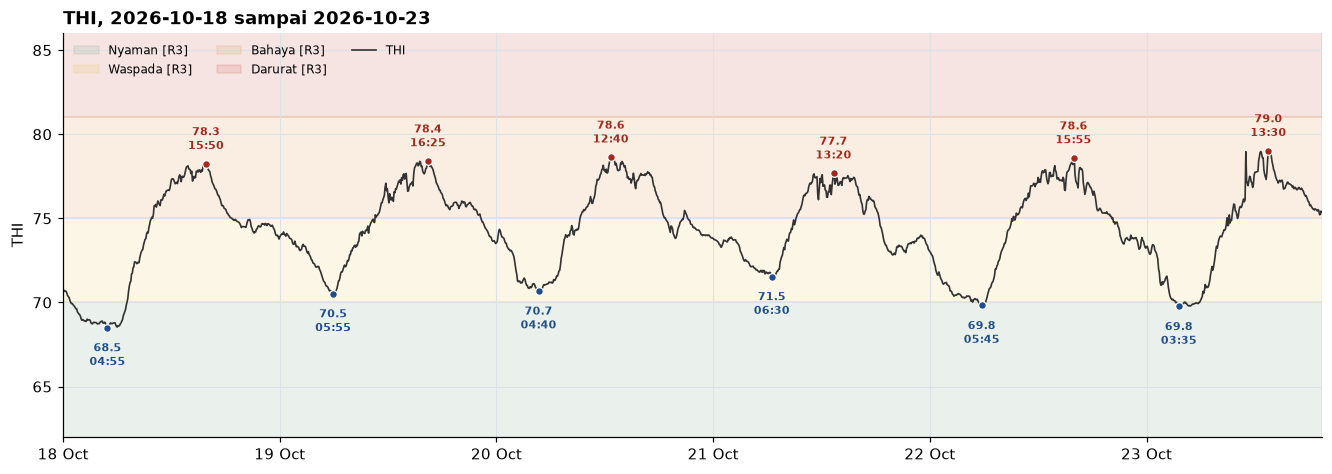

In [15]:
VAR_INFO = {
    'Suhu (°C)':        ('temp', '#d34c40', [(TN_LOW, TN_HIGH, '#6f9e7a', 'Zona nyaman 21–28 °C [R1]')], lambda v: v > TN_HIGH),
    'RH (%)':           ('rh', '#168d9b', [(RH_LOW, RH_HIGH, '#168d9b', 'Pedoman 40–60% (penyuluhan)')], lambda v: v > RH_HIGH),
    'THI':              ('thi', '#333333', [(lo if np.isfinite(lo) else 60, hi if np.isfinite(hi) else 90, c, f'{n} [R3]') for lo, hi, n, c in THI_BANDS], lambda v: v >= 75),
    'MQ-135 (mV)':      ('mq', '#7256a4', [], None),
    'Tekanan (hPa)':    ('press', '#5278b7', [], None),
}
ALL_DAYS = sorted(b['date'].unique())

def _subset(start, end):
    s = pd.Timestamp(start, tz=TZ); e = pd.Timestamp(end, tz=TZ) + pd.Timedelta(days=1)
    return b[(b.index >= s) & (b.index < e)]

def fig_timeseries(var, start, end):
    col, color, bands, _ = VAR_INFO[var]
    d = _subset(start, end)
    fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
    for lo, hi, c, lab in bands:
        ax.axhspan(lo, hi, color=c, alpha=.14, label=lab)
    ax.plot(d.index, d[col], color=color, lw=1.1, label=var)
    mark_peaks_lows(ax, d[col], '', dp=0 if col == 'mq' else 1)
    if col == 'mq':
        ax.axhline(device_thr, color='#999', ls=':', label=f'Ambang perangkat {device_thr:.1f} (bukan jurnal)')
        for bd, c in zip(bounds, ['#e5a92a', '#c2453a']):
            ax.axhline(bd, color=c, ls='--', lw=1, label=f'{bd:.0f} mV (k-means, bukan jurnal)')
    if col == 'thi':
        ax.set_ylim(62, 86)
    time_axis(ax); ax.set_ylabel(var); ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper left')
    ax.set_title(f'{var}, {start} sampai {end}', loc='left')
    return fig

def fig_dayhour(var):
    col, _, _, rule = VAR_INFO[var]
    M = day_hour(col)
    fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
    im = ax.imshow(M.values, aspect='auto', cmap='magma_r')
    ax.set_yticks(range(len(M.index)), M.index); ax.set_xticks(range(24), range(24)); ax.set_xlabel('Jam (WIB)')
    fig.colorbar(im, ax=ax, label=var)
    if rule is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M.values[i, j]) and rule(M.values[i, j]):
                    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch='///', edgecolor='white', lw=0))
    ax.set_title(f'{var} per hari × jam' + ('' if rule is None else ' (bergaris: batas jurnal terlewati)'), loc='left')
    return fig

def fig_3d(color_by, start, end):
    d = _subset(start, end)[['temp', 'rh', 'mq', 'thi']].resample('30min').median().dropna()
    fig = plt.figure(figsize=(8, 6.5)); ax = fig.add_subplot(projection='3d')
    if color_by == 'THI':
        sc = ax.scatter(d.temp, d.rh, d.mq, c=d.thi, cmap='OrRd', s=40, edgecolors='white', linewidths=.3)
        fig.colorbar(sc, ax=ax, shrink=.6, pad=.1, label='THI')
    else:
        st = state_names[np.digitize(d.mq, bounds)]
        for s in state_names:
            q = d[st == s]; ax.scatter(q.temp, q.rh, q.mq, color=state_cols[s], s=40, label=s, edgecolors='white', linewidths=.3)
        ax.legend(frameon=False, loc='upper left')
    style3d(ax, f'Suhu × RH × MQ-135 ({start} sampai {end})')
    return fig

def insight_text(start, end):
    d = _subset(start, end)
    if d.empty:
        return 'Tidak ada data pada rentang ini.'
    hot = d[d.temp > TN_HIGH]
    hot_hours = hot.index.hour.value_counts().sort_index()
    peak = d.temp.idxmax()
    lines = [f'**Rentang:** {start} sampai {end} ({len(d) * 5 / 60:.0f} jam data)', '',
             f'- Suhu di atas 28 °C [R1]: **{len(hot) * 5 / 60:.1f} jam** ({100 * len(hot) / len(d):.0f}% waktu). '
             f'Suhu tertinggi {d.temp.max():.1f} °C pada {peak:%d %b %H:%M} WIB.',
             f'- Jam yang paling sering panas: ' + (', '.join(f'{h:02d}.00' for h in hot_hours.index[hot_hours >= hot_hours.max() * .5]) if len(hot) else 'tidak ada') + '.',
             f'- THI kategori bahaya (≥ 75) [R3]: **{(d.thi >= 75).sum() * 5 / 60:.1f} jam**; THI maksimum {d.thi.max():.1f}.',
             f'- RH di atas 60%: **{(d.rh > RH_HIGH).sum() * 5 / 60:.1f} jam**, terutama malam hari.',
             f'- MQ-135 median {d.mq.median():.0f} mV; di atas 754 mV selama {(d.mq >= bounds[1]).sum() * 5 / 60:.1f} jam '
             '(relatif untuk modul ini, bukan ppm amonia).']
    return '\n'.join(lines)

# Pratinjau tanpa Gradio, untuk memastikan fungsi berjalan
fig_timeseries('THI', ALL_DAYS[2], ALL_DAYS[-1]); plt.show()
print(insight_text(ALL_DAYS[0], ALL_DAYS[-1]))

In [ ]:
# Jalankan sel ini di Jupyter setelah `pip install gradio`.
import gradio as gr

with gr.Blocks(title='Coop Monitor — Minggu 1') as demo:
    gr.Markdown('# Coop Monitor — Dashboard Minggu 1\n'
                'Batas dari publikasi: suhu 28 °C [R1], kategori THI [R3], RH 60% (penyuluhan). '
                'MQ-135 adalah respons relatif (mV), **bukan ppm amonia**.')
    with gr.Row():
        start = gr.Dropdown(ALL_DAYS, value=ALL_DAYS[0], label='Tanggal awal')
        end = gr.Dropdown(ALL_DAYS, value=ALL_DAYS[-1], label='Tanggal akhir')
    with gr.Tab('Insight'):
        insight = gr.Markdown(insight_text(ALL_DAYS[0], ALL_DAYS[-1]))
    with gr.Tab('Deret waktu'):
        var_ts = gr.Radio(list(VAR_INFO), value='Suhu (°C)', label='Variabel')
        plot_ts = gr.Plot(fig_timeseries('Suhu (°C)', ALL_DAYS[0], ALL_DAYS[-1]))
    with gr.Tab('Jam kritis'):
        var_dh = gr.Radio(list(VAR_INFO), value='THI', label='Variabel')
        plot_dh = gr.Plot(fig_dayhour('THI'))
    with gr.Tab('3D'):
        color3d = gr.Radio(['THI', 'Status MQ'], value='THI', label='Warna titik')
        plot_3d = gr.Plot(fig_3d('THI', ALL_DAYS[0], ALL_DAYS[-1]))

    def update_all(s, e, v_ts, v_dh, c3):
        if pd.Timestamp(s) > pd.Timestamp(e):
            s, e = e, s
        plt.close('all')
        return insight_text(s, e), fig_timeseries(v_ts, s, e), fig_dayhour(v_dh), fig_3d(c3, s, e)

    inputs = [start, end, var_ts, var_dh, color3d]
    outputs = [insight, plot_ts, plot_dh, plot_3d]
    for comp in inputs:
        comp.change(update_all, inputs, outputs)

demo.launch(inline=True)

## 8. Kesimpulan singkat

- **RH memengaruhi respons MQ-135.** Korelasinya positif setiap hari dan tetap positif pada selisih 30 menit (uji permutasi), jadi bukan sekadar efek siklus harian. Arah ini sesuai dengan sifat sensor oksida logam yang resistansinya turun saat kelembapan naik [R5].
- **Efek suhu tidak bisa dipisahkan.** Suhu dan RH berkorelasi negatif kuat, dan pada selisih 30 menit korelasi suhu–MQ mendekati nol.
- **Suhu kandang** sering melewati batas atas zona nyaman broiler (28 °C) pada siang hari, dan THI sering masuk kategori waspada atau bahaya (lihat tabel di bagian 3).
- **Ambang k-means** (sekitar 729 dan 754 mV) jauh lebih membedakan daripada ambang lama 695,5 mV, yang terlewati hampir sepanjang waktu. Ambang ini hanya berlaku untuk modul `mq135-01` dan masih berupa usulan.

## Daftar pustaka

DOI diperiksa melalui Crossref pada 13 November 2026. Batas literatur lima tahun (sejak November 2021) dipakai untuk sumber jurnal; sumber yang lebih lama disebut hanya sebagai asal rumus atau kategori.

| No | Referensi | Dipakai untuk |
|---|---|---|
| R1 | Apalowo, O. O., Ekunseitan, D. A., & Fasina, Y. O. (2024). Impact of heat stress on broiler chicken production. *Poultry*, 3(2), 107–128. https://doi.org/10.3390/poultry3020010 | Zona nyaman suhu broiler 21–28 °C |
| R2 | Brugaletta, G., Teyssier, J.-R., Rochell, S. J., dkk. (2022). A review of heat stress in chickens. Part I: Insights into physiology and gut health. *Frontiers in Physiology*, 13, 934381. https://doi.org/10.3389/fphys.2022.934381 | Peran RH dalam stres panas |
| R3 | Kim, H.-R., Ryu, C., Lee, S.-D., dkk. (2024). Effects of heat stress on the laying performance, egg quality, and physiological response of laying hens. *Animals*, 14(7), 1076. https://doi.org/10.3390/ani14071076 | Kategori THI ayam petelur |
| R4 | Bist, R. B., Subedi, S., Chai, L., dkk. (2023). Ammonia emissions, impacts, and mitigation strategies for poultry production: A critical review. *Journal of Environmental Management*, 328, 116919. https://doi.org/10.1016/j.jenvman.2022.116919 | Batas amonia 25 ppm |
| R5 | Wang, Y., & Zhou, Y. (2022). Recent progress on anti-humidity strategies of chemiresistive gas sensors. *Materials*, 15(24), 8728. https://doi.org/10.3390/ma15248728 | Pengaruh kelembapan pada sensor gas oksida logam (jenis MQ-135) |
| R6 | Kusuma, dkk. (2023). Evaluating the accuracy of BMP280 and BME280 sensors for sea level in a coastal environment: A field study at Tanjung Siambang Pier. *Ilmu Kelautan: Indonesian Journal of Marine Sciences*, 28(2), 189–202. https://doi.org/10.14710/ik.ijms.28.2.189-202 | Akurasi tekanan BMP280 terhadap stasiun BMKG |
| R7 | Rawdhan, S. A., Abdelhamid, M. A., Fulaieh, M. S., dkk. (2026). Monitoring environmental parameters in poultry houses using IoT. *Agricultural Engineering*, 30(1), 79–90. https://doi.org/10.2478/agriceng-2026-0005 | Contoh sistem IoT kandang dengan MQ-135 dan ESP32 |
| R8 | Heck, J., Rauch, E., Piller, A., dkk. (2026). Levels of two pollutant gases, temperature, and relative humidity and their influence on broiler welfare. *Journal of Applied Poultry Research*, 35(2), 100694. https://doi.org/10.1016/j.japr.2026.100694 | Hubungan gas, suhu, RH dan kesejahteraan broiler (hanya metadata yang dicek) |

**Lembar data sensor (tidak ber-DOI):**
- Hanwei Electronics. *MQ-135 Gas Sensor — Technical Data.* Sensor SnO₂ untuk NH₃, NOx, alkohol, benzena, asap, CO₂; kurva sensitivitas bergantung pada suhu dan RH.
- Aosong (ASAIR). *AHT20 Humidity and Temperature Sensor Datasheet.* Akurasi tipikal ±0,3 °C dan ±2 %RH.
- Bosch Sensortec. *BMP280 Digital Pressure Sensor Datasheet (BST-BMP280-DS001).* Akurasi absolut tekanan ±1 hPa, suhu ±1,0 °C.

**Sumber asal rumus/kategori (lebih tua dari lima tahun):** NRC (1971) untuk rumus THI; Zulovich, J. M., & DeShazer, J. A. (1990), ASAE Paper No. 90-4021, untuk kategori THI yang dikutip R3.